# Fine-tuning para classificação de decisões judiciais de Habeas Corpus do STJ

**Período:** 01/2021 a 06/2026

**Dataset:** 6.220 registros de decisões de HC

**Aceleradores de Hardware - Ordem de Custo**

1. CPU
2. GPUs: T4
2. GPUs: L4
4. TPU v5e-1
5. TPU v6e-1
6. GPUs: A100
7. GPUs: G4
8. GPUs: H100

##Parametrização

In [ ]:
BASE_PATH_GENERAL = '/content/drive/MyDrive/_Mestrado PUCPR/'
BASE_PATH_DATASET = f'{BASE_PATH_GENERAL}Datasets/'
#MODEL_CHECKPOINT = 'raquelsilveira/legalbertpt_fp'
#MODEL_CHECKPOINT = 'neuralmind/bert-large-portuguese-cased' #BERTimbau
MODEL_CHECKPOINT = 'rufimelo/Legal-BERTimbau-large'
MODEL_NAME_SAVED = 'decision_HC_STJ_finetuned_large-portuguese-cased'

TEST_SIZE_SPLIT = 0.20 # Reduzido para 20% para maximizar os dados de treino
RANDOM_SEED = 42
EPOCHS = 200
LAYERS_TO_FREEZE = 22 # Etapa preliminar: congela 22 camadas e ajusta apenas as 2 camadas do topo do BERT
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EARLY_STOPPING = 5
class_names = ['Desfavorável ao Réu', 'Favorável ao Réu']
MAX_LEN = 512

# Performance knobs
NUM_WORKERS = 2
USE_TORCH_COMPILE = False

In [2]:
# Silenciar warings
import warnings
warnings.filterwarnings('ignore')

In [3]:
#!pip install transformers

In [4]:
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from pylab import rcParams

In [5]:
# Padronização dos Gráficos
%config InlineBackend.figure_format='retina'

sns.set(style='whitegrid', palette='muted', font_scale=1.2)
COLORS_PALETTE = ["#0098CC", "#CCA100", "#CC6400", "#CC0057", "#8ACC02", "#7200CC"]
sns.set_palette(sns.color_palette(COLORS_PALETTE))
rcParams['figure.figsize'] = 12, 8

In [6]:
# Garante que processos que dependem de aleatoriedade gerem sempre o mesmo resultado,
#   caso ocorra a execução do notebook novamente.

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Permite kernels mais rápidos em GPUs NVIDIA recentes sem afetar a precisão final para este caso
if device.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
# O pré-processamento textual já foi realizado, porém, se for necessário remover
#   a pontuação (no caso de testes com modelos rasos), o pré-processamento pode
#   ser acionando novamente com o parâmetro mantem_pontuacao = 'N'.

# %run "{BASE_PATH_GENERAL}libs/preprocessing_pucpr.ipynb"

In [10]:
import pandas as pd
import os

# Define the correct file path
#file_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_undersampling_2021_2026.csv"
file_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_geral_.csv"

df = None
loaded_from = None

if os.path.exists(file_path):
    try:
        df = pd.read_csv(file_path, sep=';')
        loaded_from = file_path
        print(f"✅ Arquivo carregado com sucesso de: {file_path}")
        print(f"Shape: {df.shape}")
        display(df.head(3))
    except Exception as e:
        print(f"❌ Erro ao ler {file_path}: {e}")
else:
    print(f"⚠️ Arquivo CSV não encontrado no caminho: {file_path}")
    print("Por favor, verifique se o arquivo existe ou o caminho está correto.")

✅ Arquivo carregado com sucesso de: /content/drive/MyDrive/_Mestrado PUCPR/Datasets/preprocessed_acordaos_HC_geral_.csv
Shape: (86854, 20)


,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,DATARECEBIMENTO,DATADISTRIBUICAO,MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,ASSUNTOS,NUM_DIAS_CONCLUSAO_PROCESSO,TIPOPROCESSO,NUMEROPROCESSO,ACORDAO,EMENTA,RELATORIO,VOTO,DECISAO,DECISAO_FAVORAVEL
0,91690725,2021-06-07,ACORDAO,201801484120,2018-06-19,2018-06-19,LAURITA VAZ,NaN,Concedendo,NaN,"01209.07942., 01209.07942.07791.",1084,HC,455097,NaN,HABEAS CORPUS. PENAL. MEDIDA CAUTELAR DE RECOL...,A EXMA. SRA. MINISTRA LAURITA VAZ:Trata-se hab...,-VISTAO SENHOR MINISTRO ROGERIO SCHIETTI CRUZ:...,NaN,S
1,102059939,2021-04-28,ACORDAO,201902095120,2019-07-18,2019-07-18,LAURITA VAZ,AgRg,Negando,NaN,"01209.07942.07791., 01209.07942.",650,HC,522084,NaN,AGRAVO REGIMENTAL EM HABEAS CORPUS. EXECUÇÃO P...,A EXMA. SRA. MINISTRA LAURITA VAZ:Trata-se de ...,A EXMA. SRA. MINISTRA LAURITA VAZ (RELATORA):A...,NaN,N
2,104013501,2021-08-10,ACORDAO,201800793060,2018-04-09,2018-04-09,LAURITA VAZ,NaN,Negando,NaN,"00287.03547.03555., 00287.03520.03521.",1219,HC,444275,NaN,HABEAS CORPUS. PROCESSUAL PENAL. CORRUPÇÃO PAS...,A EXMA. SRA. MINISTRA LAURITA VAZ:Trata-se de ...,O SENHOR MINISTRO FELIX FISCHER: A decisão agr...,NaN,N


In [11]:
#Listar os nomes unícos dos ministros
ministros_unicos = df['MINISTRO'].unique()
print(ministros_unicos)

['LAURITA VAZ' 'OLINDO MENEZES (DESEMBARGADOR '
 'ANTONIO SALDANHA PALHEIRO' 'SEBASTIÃO REIS JÚNIOR' 'RAUL ARAÚJO'
 'HERMAN BENJAMIN' 'ROGERIO SCHIETTI CRUZ' 'REYNALDO SOARES DA FONSECA'
 'NEFI CORDEIRO' 'RIBEIRO DANTAS' 'JOÃO OTÁVIO DE NORONHA' 'FELIX FISCHER'
 'JOEL ILAN PACIORNIK' 'MAURO CAMPBELL MARQUES' 'ASSUSETE MAGALHÃES'
 'GURGEL DE FARIA' 'JORGE MUSSI' 'MARCO AURÉLIO BELLIZZE'
 'FRANCISCO FALCÃO' 'HUMBERTO MARTINS' 'JESUÍNO RISSATO (DESEMBARGADOR'
 'MANOEL ERHARDT (DESEMBARGADOR ' 'NANCY ANDRIGHI' 'SÉRGIO KUKINA'
 'PAULO DE TARSO SANSEVERINO' 'REGINA HELENA COSTA' 'BENEDITO GONÇALVES'
 'OG FERNANDES' 'MESSOD AZULAY NETO' 'JOÃO BATISTA MOREIRA  (DESEMBA'
 'MOURA RIBEIRO' 'MARIA ISABEL GALLOTTI' 'MARCO BUZZI'
 'TEODORO SILVA SANTOS' 'MARIA THEREZA DE ASSIS MOURA' 'DANIELA TEIXEIRA'
 'PAULO SÉRGIO DOMINGUES' 'ANTONIO CARLOS FERREIRA'
 'OTÁVIO DE ALMEIDA TOLEDO (DESE' 'LUIS FELIPE SALOMÃO'
 'CARLOS CINI MARCHIONATTI (DESE' 'AFRÂNIO VILELA' 'CARLOS PIRES BRANDÃO'
 'MARIA MARLUCE CA

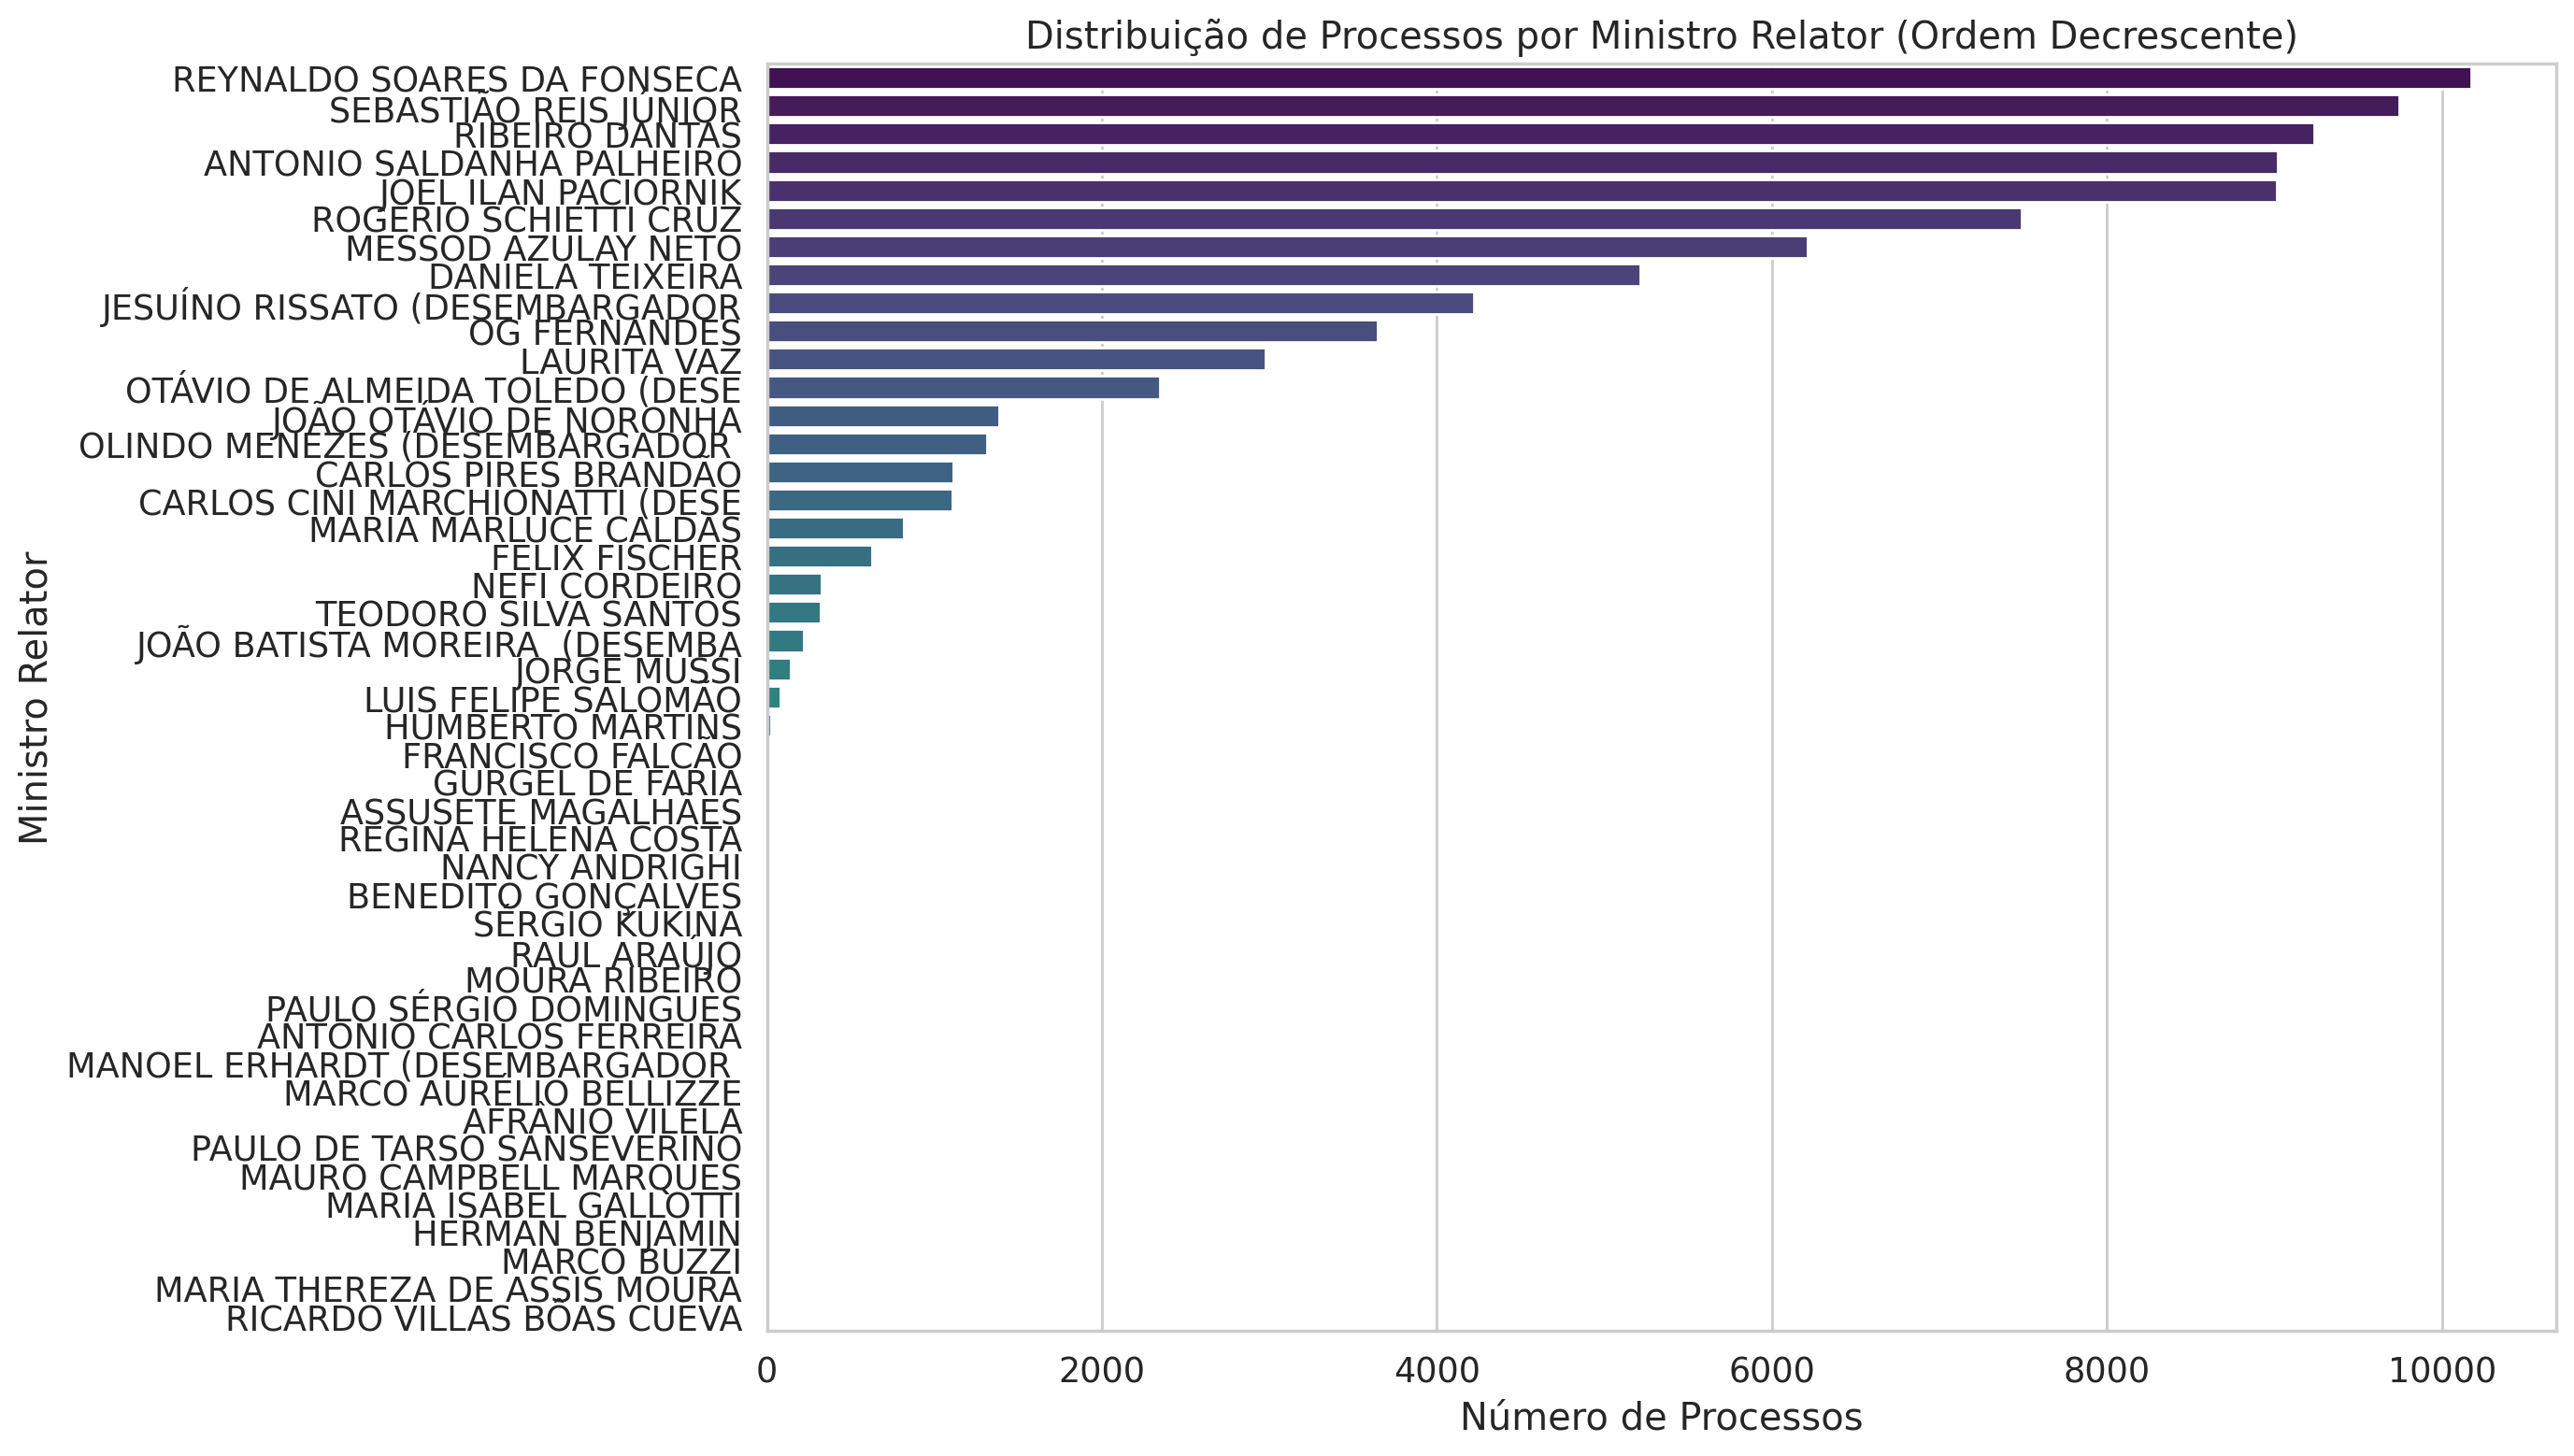

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

minister_col = 'MINISTRO'

plt.figure(figsize=(14, 8))
# Calcula a distribuição de processos e ordena de forma DECRESCENTE (mais processos primeiro)
minister_counts = df[minister_col].value_counts().sort_values(ascending=False)

# Gera o gráfico de barras horizontais respeitando a ordem decrescente no eixo Y
sns.barplot(y=minister_counts.index, x=minister_counts.values, palette='viridis', order=minister_counts.index)
plt.title('Distribuição de Processos por Ministro Relator (Ordem Decrescente)')
plt.xlabel('Número de Processos')
plt.ylabel('Ministro Relator')
plt.tight_layout()
plt.show()

In [13]:
print("\nMétricas de distribuição de processos por Ministro Relator:")
print(f"Mínimo: {minister_counts.min():.0f} processos")
print(f"Máximo: {minister_counts.max():.0f} processos")
print(f"Média: {minister_counts.mean():.2f} processos")
print(f"Mediana: {minister_counts.median():.2f} processos")
print(f"Desvio Padrão: {minister_counts.std():.2f} processos")


Métricas de distribuição de processos por Ministro Relator:
Mínimo: 1 processos
Máximo: 10172 processos
Média: 1930.09 processos
Mediana: 79.00 processos
Desvio Padrão: 3210.63 processos


Distribuição da Classe DECISAO_FAVORAVEL:
N: 83593 (96.25%)
S: 3261 (3.75%)


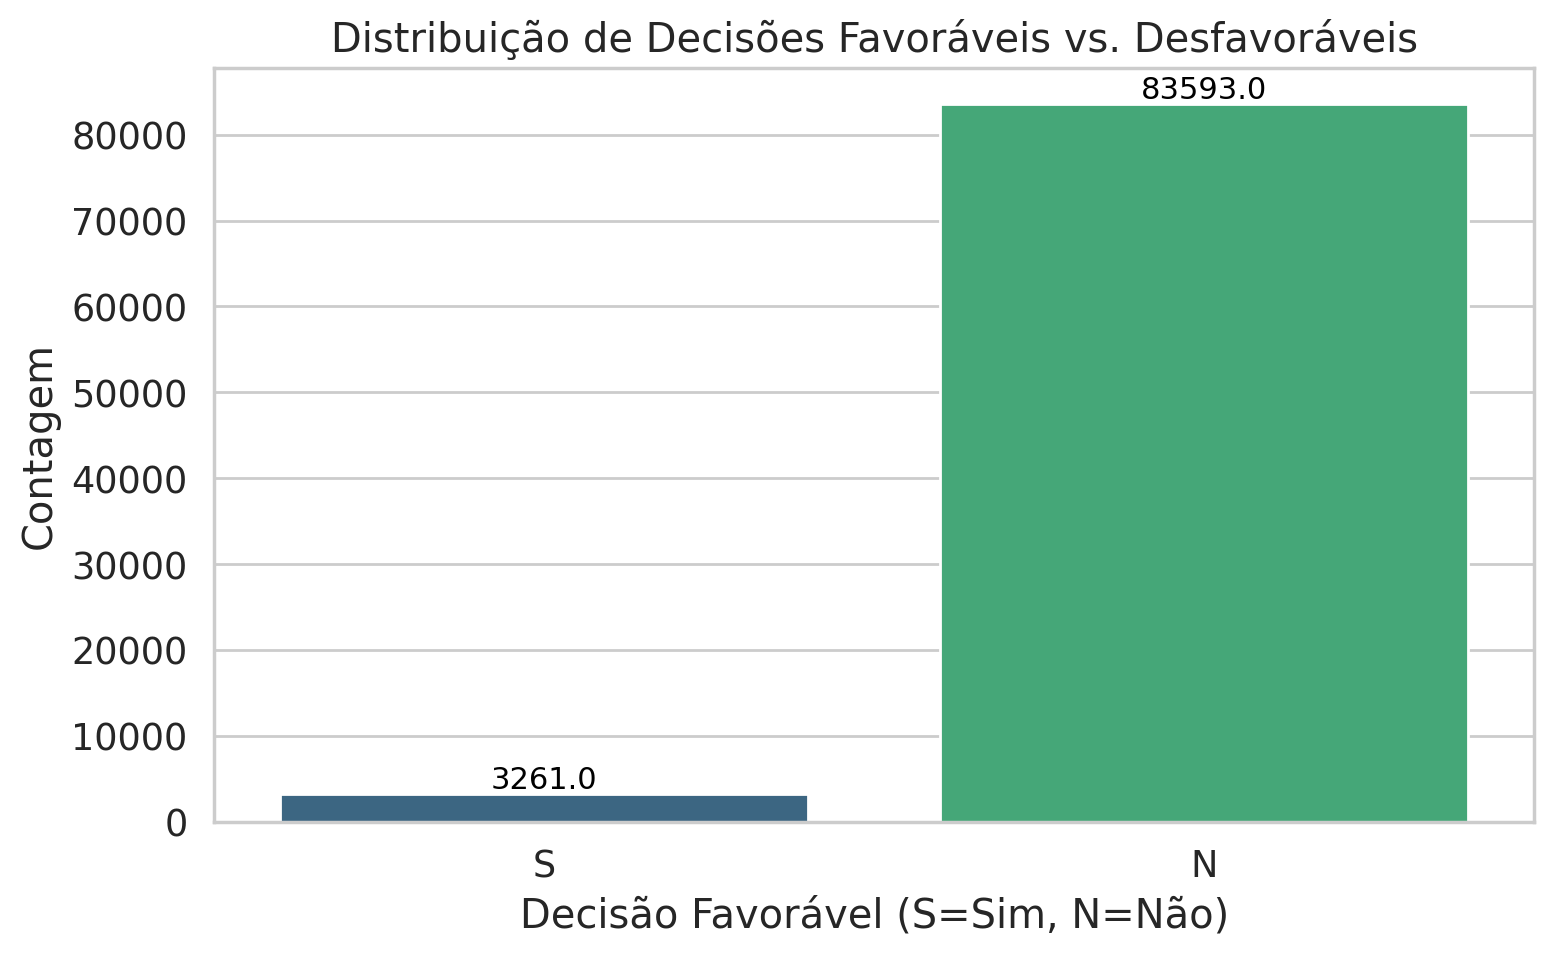

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate distribution
class_counts = df['DECISAO_FAVORAVEL'].value_counts()
class_percents = df['DECISAO_FAVORAVEL'].value_counts(normalize=True) * 100

print("Distribuição da Classe DECISAO_FAVORAVEL:")
for idx, val in class_counts.items():
    print(f"{idx}: {val} ({class_percents[idx]:.2f}%)")

# Visualize the distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='DECISAO_FAVORAVEL', data=df, palette='viridis')
plt.title('Distribuição de Decisões Favoráveis vs. Desfavoráveis')
plt.xlabel('Decisão Favorável (S=Sim, N=Não)')
plt.ylabel('Contagem')

# Add percentage labels on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

Total de registros original: 86854
Registros após proteger 'S' e filtrar 'N' (Piso: 100, Teto: 2000): 27265
Distribuição atual: S=2725 | N=24540


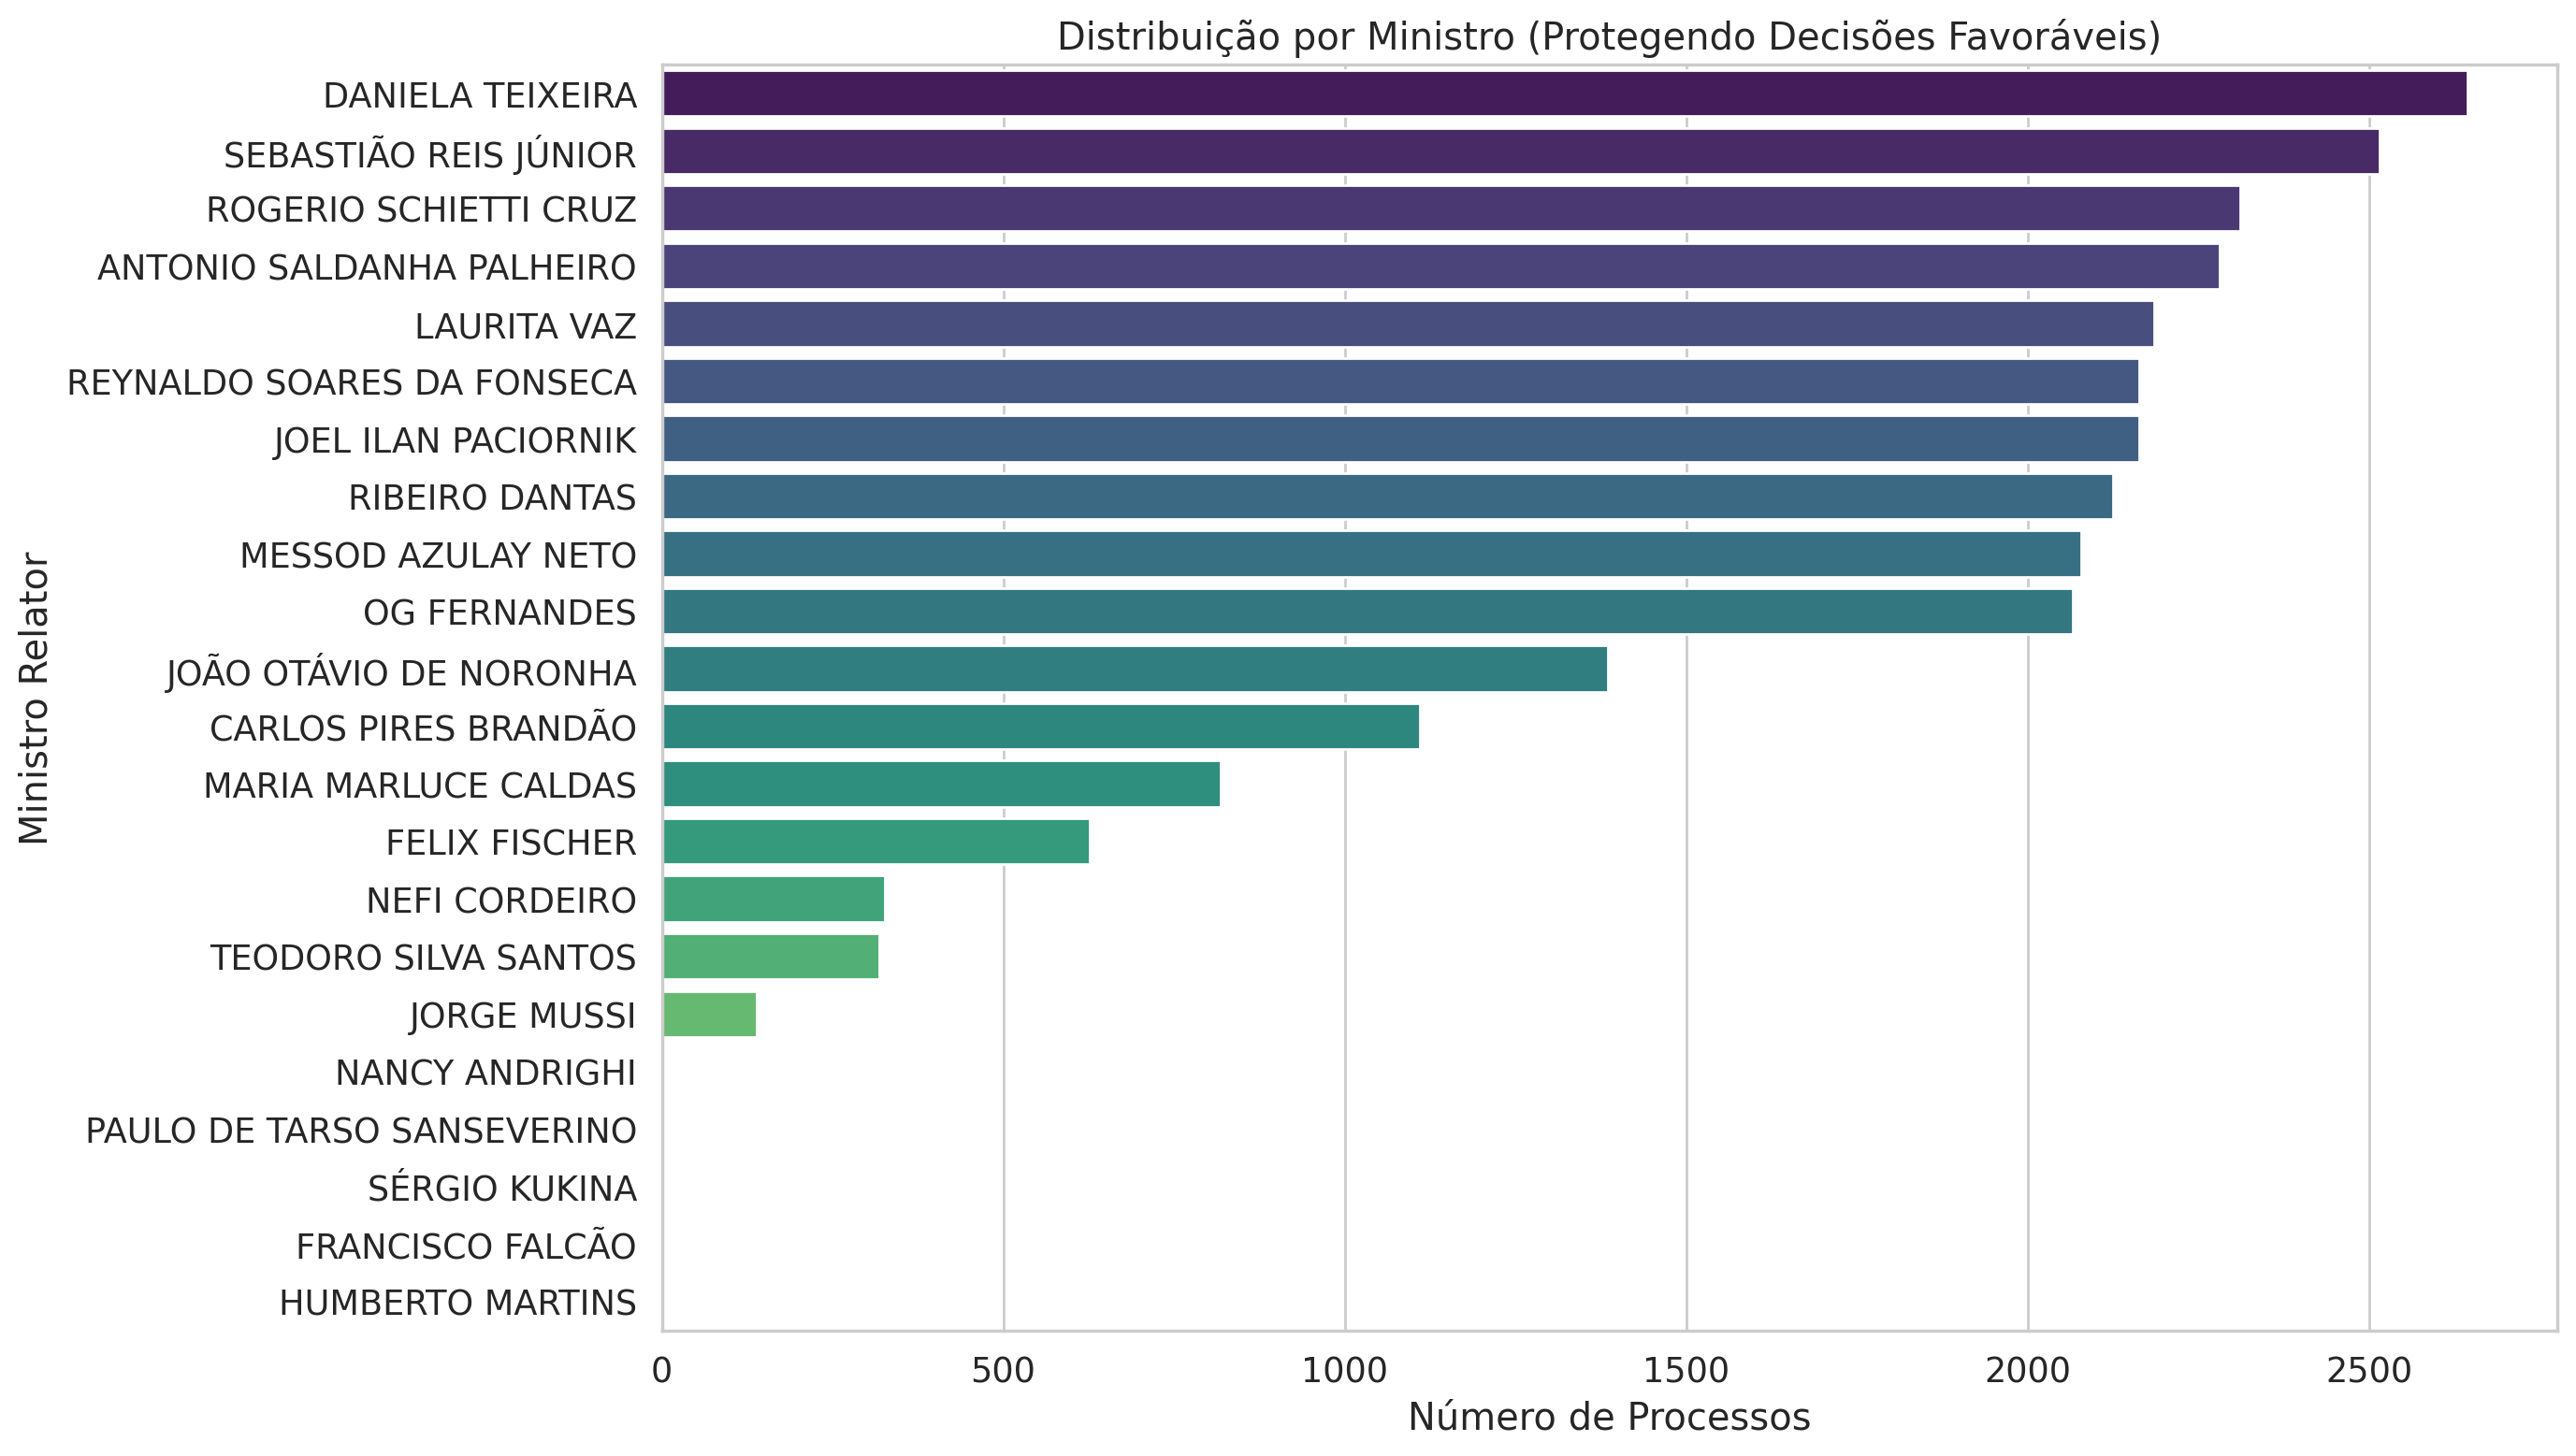

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Novos pontos de corte sugeridos
min_processos = 100
max_processos = 2000

print(f"Total de registros original: {len(df)}")

# 1. Remoção de Desembargadores
df = df[~df[minister_col].str.contains(' (DESE', case=False, na=False, regex=False)].copy()

# 2. Separação para proteger a classe 'S' (Favorável)
df_S_all = df[df['DECISAO_FAVORAVEL'] == 'S'].copy()
df_N_only = df[df['DECISAO_FAVORAVEL'] == 'N'].copy()

# 3. Corte Mínimo e Teto Máximo apenas na classe 'N'
# Isso garante que não perderemos 'S' por baixa produtividade do ministro ou por amostragem
contagem_N = df_N_only[minister_col].value_counts()
ministros_validos_N = contagem_N[contagem_N >= min_processos].index
df_N_filtrado = df_N_only[df_N_only[minister_col].isin(ministros_validos_N)].copy()

def sample_minister_N(group):
    if len(group) > max_processos:
        return group.sample(n=max_processos, random_state=RANDOM_SEED)
    return group

df_N_balanceado = df_N_filtrado.groupby(minister_col, group_keys=False).apply(sample_minister_N)

# 4. Recombinação (Mantendo todos os 'S' e os 'N' filtrados/balanceados)
df = pd.concat([df_S_all, df_N_balanceado]).reset_index(drop=True)

print(f"Registros após proteger 'S' e filtrar 'N' (Piso: {min_processos}, Teto: {max_processos}): {len(df)}")
print(f"Distribuição atual: S={len(df[df['DECISAO_FAVORAVEL']=='S'])} | N={len(df[df['DECISAO_FAVORAVEL']=='N'])}")

# 5. Visualiza a distribuição por ministro (final)
plt.figure(figsize=(14, 8))
minister_counts_new = df[minister_col].value_counts()
sns.barplot(y=minister_counts_new.index, x=minister_counts_new.values, palette='viridis')
plt.title('Distribuição por Ministro (Protegendo Decisões Favoráveis)')
plt.xlabel('Número de Processos')
plt.ylabel('Ministro Relator')
plt.tight_layout()
plt.show()

Distribuição Atual da Classe DECISAO_FAVORAVEL:
N: 24540 (90.01%)
S: 2725 (9.99%)


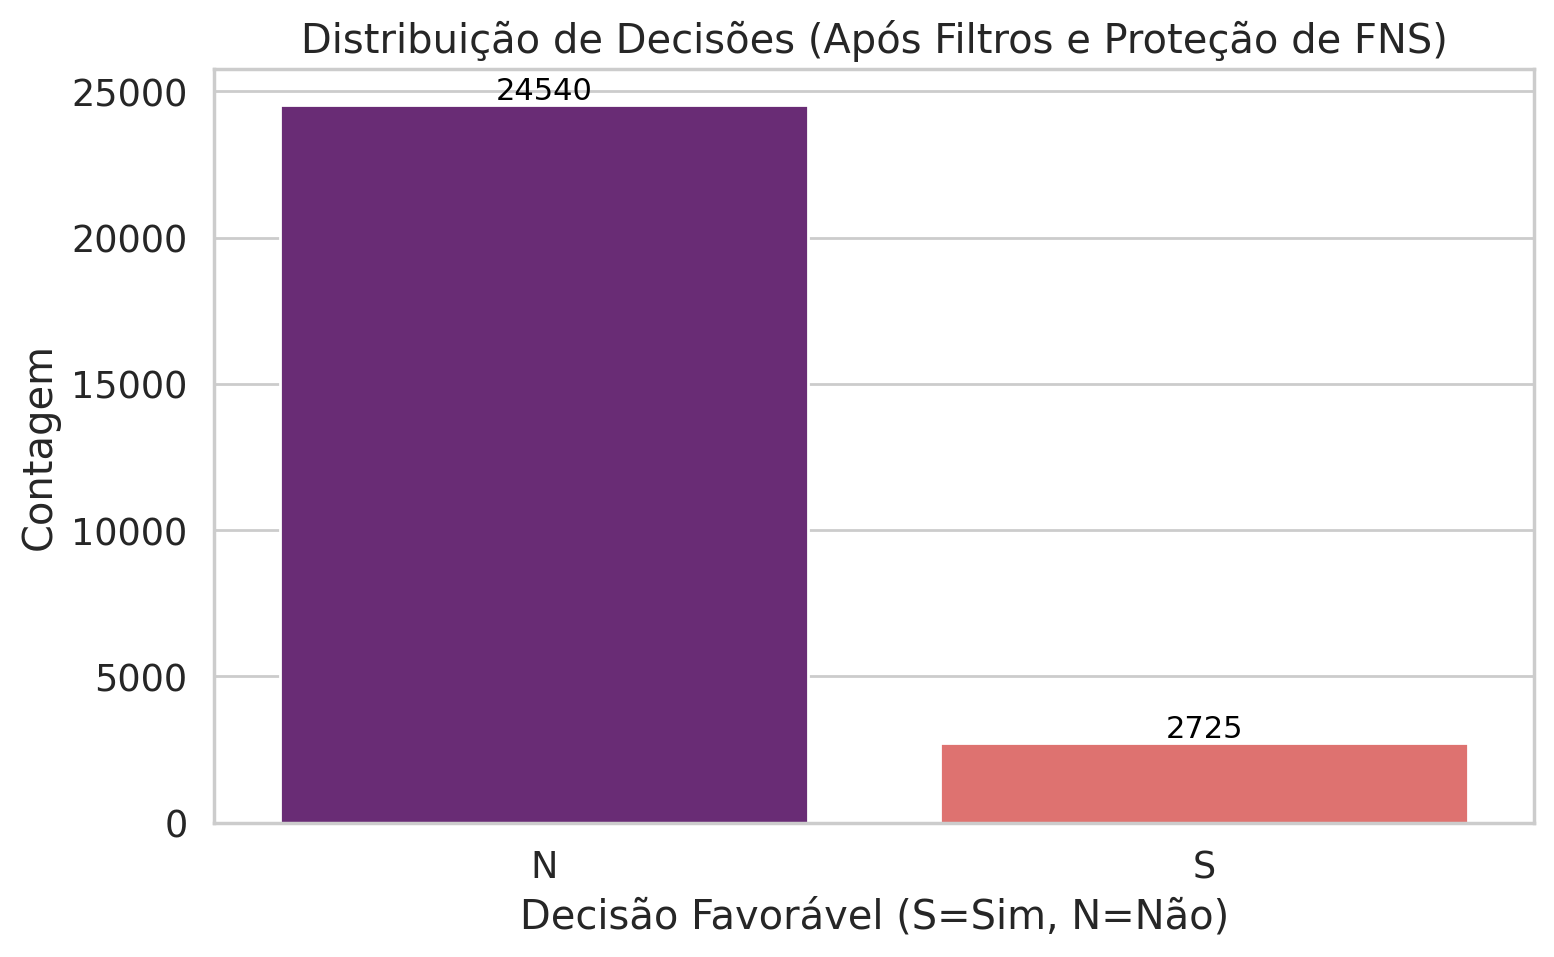

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Cálculo da distribuição atual no dataframe df
class_counts_final = df['DECISAO_FAVORAVEL'].value_counts()
class_percents_final = df['DECISAO_FAVORAVEL'].value_counts(normalize=True) * 100

print("Distribuição Atual da Classe DECISAO_FAVORAVEL:")
for idx, val in class_counts_final.items():
    print(f"{idx}: {val} ({class_percents_final[idx]:.2f}%)")

# Visualização
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='DECISAO_FAVORAVEL', data=df, palette='magma', order=['N', 'S'])
plt.title('Distribuição de Decisões (Após Filtros e Proteção de FNS)')
plt.xlabel('Decisão Favorável (S=Sim, N=Não)')
plt.ylabel('Contagem')

# Adicionar rótulos de valores nas barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

In [17]:
import pandas as pd

# 1. Identificar o tamanho da classe minoritária ('S') após os filtros
final_size_s = len(df[df['DECISAO_FAVORAVEL'] == 'S'])

# 2. Separar as classes
df_s_final = df[df['DECISAO_FAVORAVEL'] == 'S']
df_n_final = df[df['DECISAO_FAVORAVEL'] == 'N']

# 3. Aplicar Undersampling na classe 'N' para igualar à 'S'
df_n_undersampled = df_n_final.sample(n=final_size_s, random_state=RANDOM_SEED)

# 4. Concatenar e embaralhar o dataset final
df_balanced = pd.concat([df_s_final, df_n_undersampled]).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

# 5. NOVO: Excluir ministros que possuem apenas um registro (evitar ruído de um único dado)
counts = df_balanced[minister_col].value_counts()
valid_ministers = counts[counts > 1].index
df_balanced = df_balanced[df_balanced[minister_col].isin(valid_ministers)].reset_index(drop=True)

# Atualizar o df principal
df = df_balanced

print("Balanceamento Final de Classes e Filtro de Registros Únicos Concluído:")
print(df['DECISAO_FAVORAVEL'].value_counts())
print(f"\nTotal de registros prontos para treinamento: {len(df)}")

Balanceamento Final de Classes e Filtro de Registros Únicos Concluído:
DECISAO_FAVORAVEL
N    2725
S    2720
Name: count, dtype: int64

Total de registros prontos para treinamento: 5445


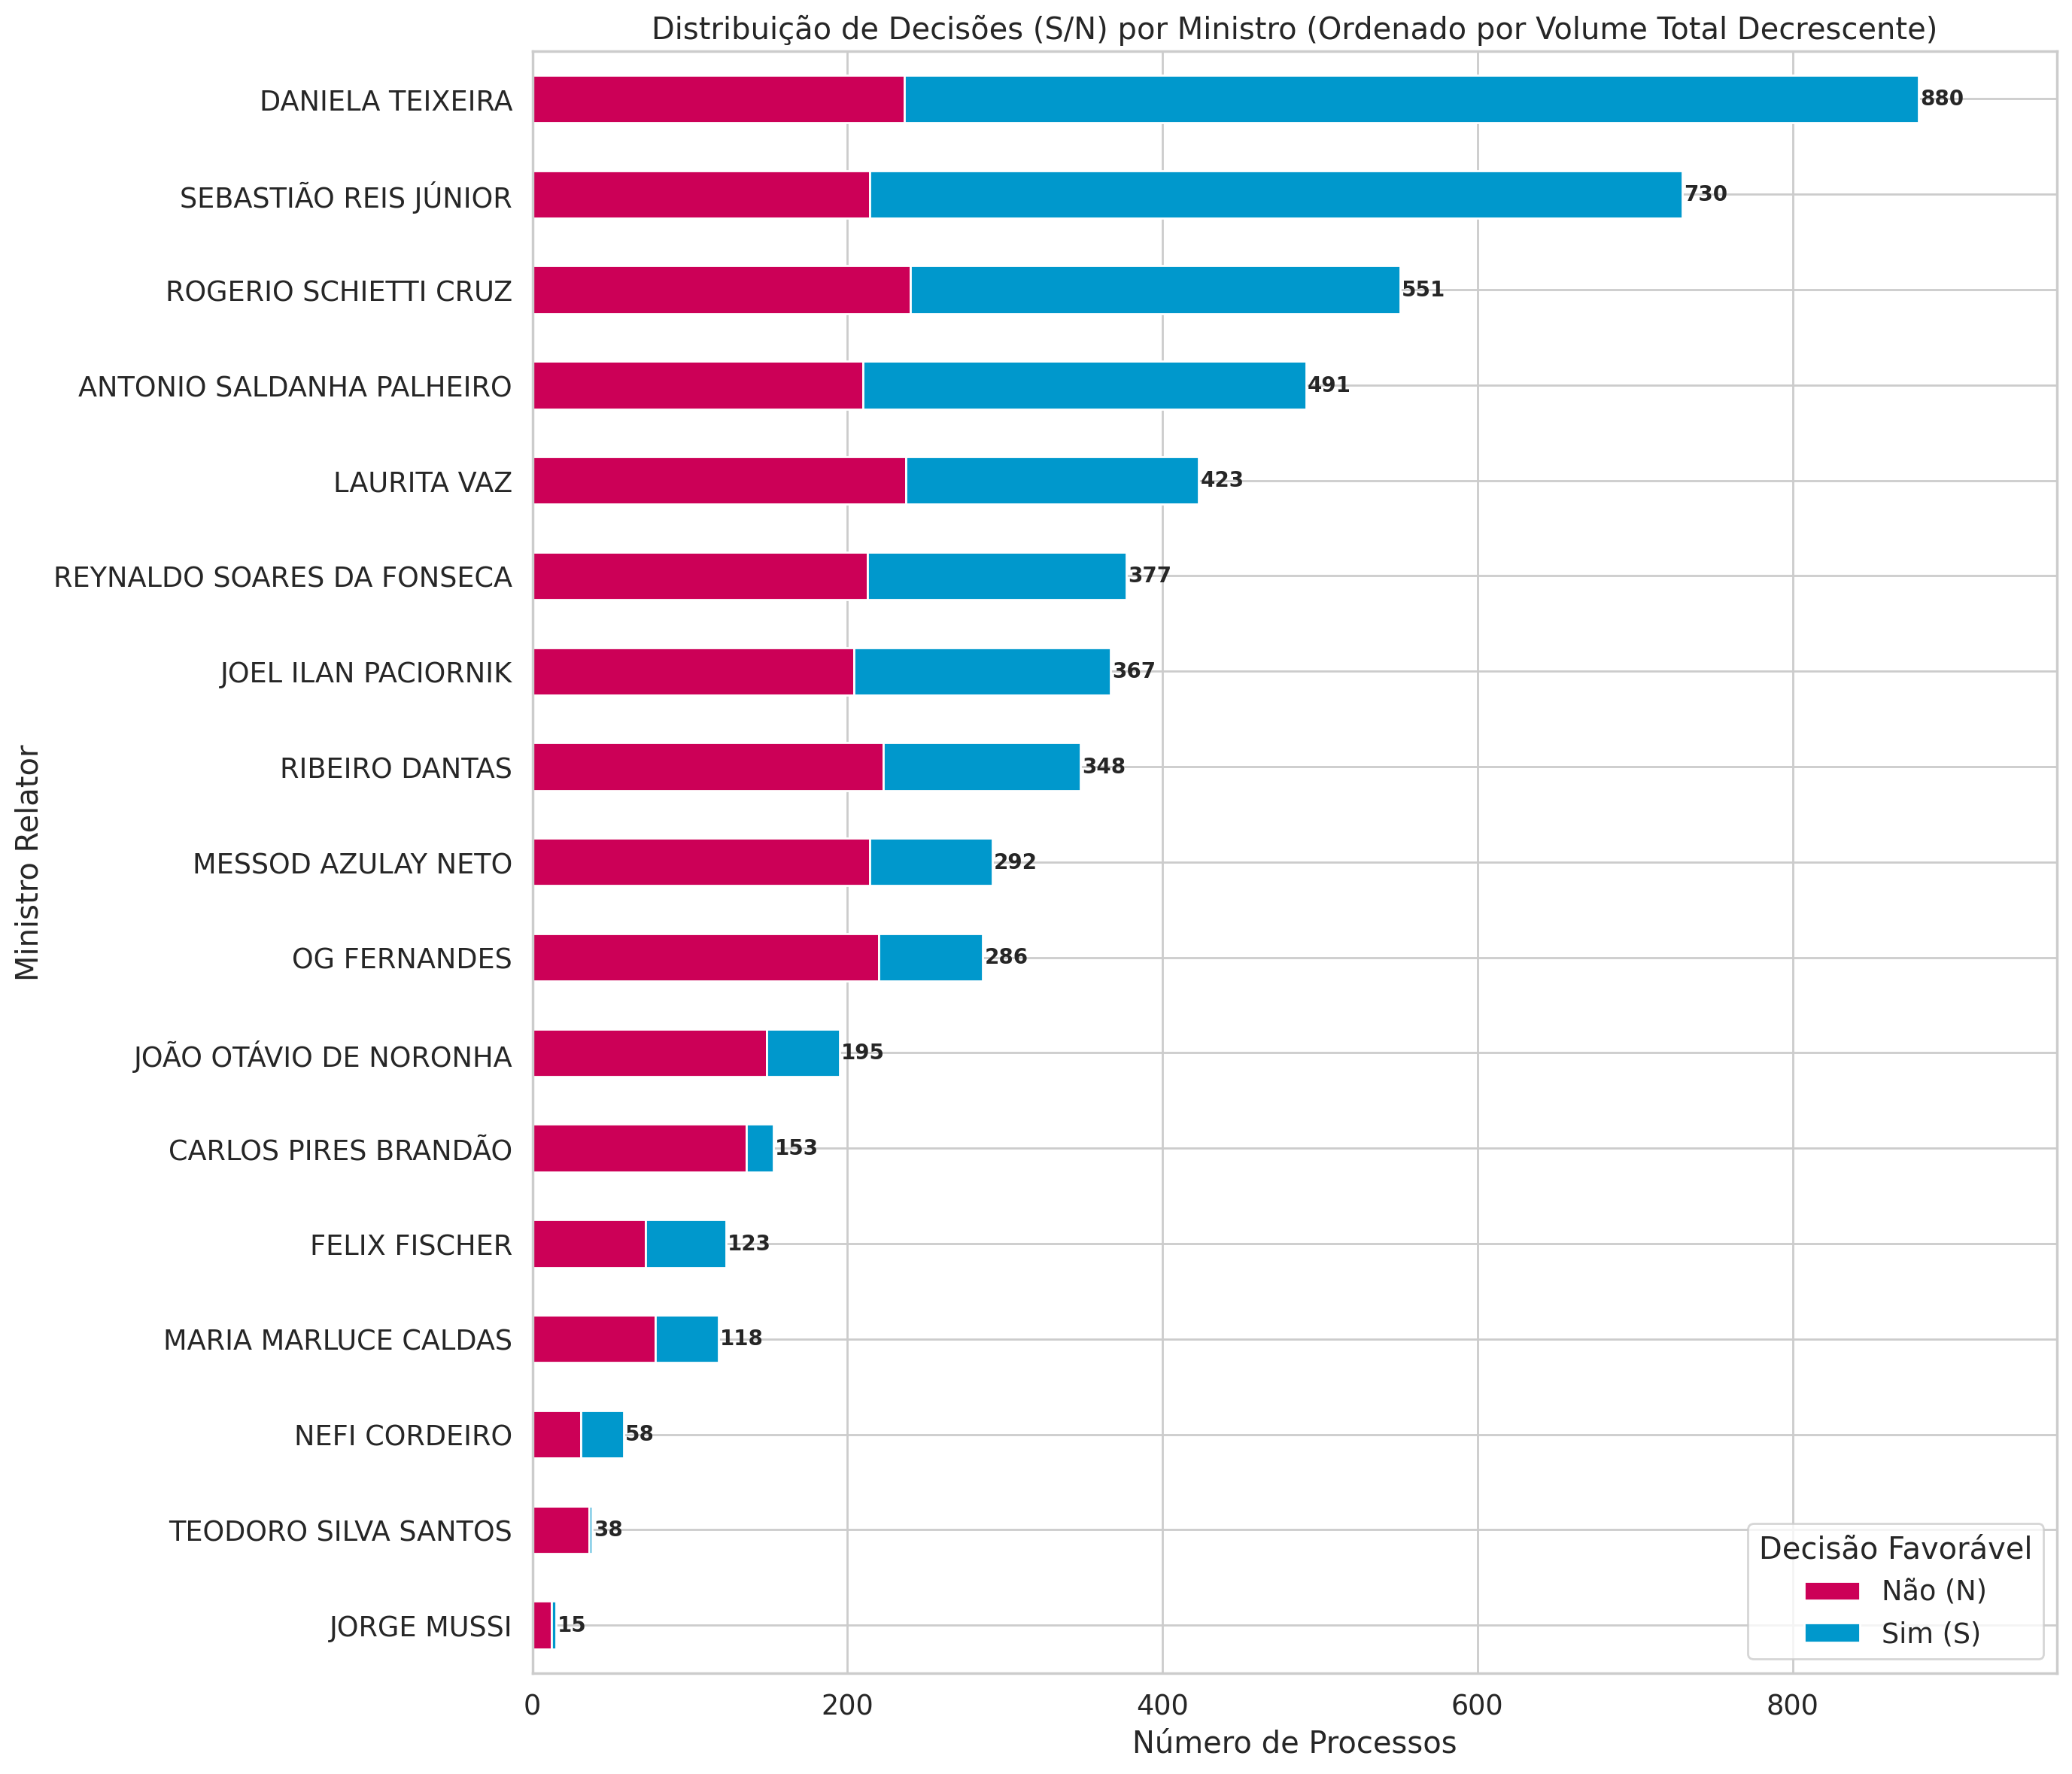

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

minister_col = 'MINISTRO'

# Calculando os totais para ordenar o gráfico de barras empilhadas de forma DECRESCENTE
minister_totals = df.groupby(minister_col).size().sort_values(ascending=False)

# Reordenando o dataframe de distribuição com base nos totais (invertendo a ordem para o gráfico de barras horizontais subir o maior)
# No matplotlib barh, o primeiro item do index fica na base, então invertemos para o maior ficar no topo
minister_decision_dist = df.groupby([minister_col, 'DECISAO_FAVORAVEL']).size().unstack(fill_value=0)
minister_decision_dist = minister_decision_dist.reindex(minister_totals.index[::-1])
ordered_totals = minister_totals.iloc[::-1]

# Plotagem
plt.figure(figsize=(14, 12))
ax = minister_decision_dist.plot(kind='barh', stacked=True, color=['#CC0057', '#0098CC'], ax=plt.gca())

# Adicionando rótulos de totais ao final de cada barra
for i, (name, total) in enumerate(ordered_totals.items()):
    ax.text(total + 1, i, f'{int(total)}', va='center', fontsize=10, fontweight='bold')

plt.title('Distribuição de Decisões (S/N) por Ministro (Ordenado por Volume Total Decrescente)')
plt.xlabel('Número de Processos')
plt.ylabel('Ministro Relator')
plt.legend(title='Decisão Favorável', labels=['Não (N)', 'Sim (S)'], loc='lower right')

# Ajuste de limite do eixo X para acomodar os labels
plt.xlim(0, minister_totals.max() * 1.1)

plt.tight_layout()
plt.show()

### Justificativa Metodológica: Mitigação de Viés Representacional e Balanceamento de Autoria

A etapa de pré-processamento supracitada aplica uma técnica de amostragem híbrida com o intuito de mitigar potenciais vieses algorítmicos (*algorithmic bias*) decorrentes da distribuição assimétrica do volume processual entre os relatores. A literatura em Processamento de Linguagem Natural (PLN) aplicado ao domínio jurídico adverte para o risco de modelos baseados na arquitetura *Transformer* (como o BERT) internalizarem padrões estilométricos (estilo de escrita) ou correlações espúrias associadas a magistrados super-representados no *dataset*.

A estratégia metodológica final adotada divide-se em quatro frentes complementares:

1. **Exclusão de Desembargadores Convocados:** Magistrados convocados temporariamente apresentam assinaturas estilométricas distintas dos membros titulares da Corte. Sua remoção contribui para a homogeneização estrutural da amostra.
2. **Proteção da Classe Minoritária e Filtragem da Majoritária:** Todas as decisões favoráveis ('S') foram mantidas integralmente. Os cortes de piso (mínimo de 100) e teto (máximo de 2000, via *Random Undersampling*) foram aplicados exclusivamente à classe desfavorável ('N'). Isso previne o *overfitting* no estilo de ministros muito produtivos sem sacrificar os dados raros.
3. **Balanceamento Definitivo de Classes (50/50):** Subamostragem aleatória final da classe 'N' filtrada para parear exatamente com a contagem da classe 'S', assegurando que o modelo não desenvolva preferência por nenhuma das classes durante o treinamento.
4. **Filtro de Unicidade (Poda de Ruído):** Exclusão de magistrados que, após todo o processo de balanceamento, acabaram com apenas 1 registro no *dataset*. Isso garante suporte empírico mínimo para a generalização dos padrões textuais associados a cada autor.

In [19]:
total   = df.shape[0]
label_s = df[df['DECISAO_FAVORAVEL']  == 'S'].shape[0]
label_n = df[df['DECISAO_FAVORAVEL']  == 'N'].shape[0]

print(f'TOTAL  : {total}')
print(f'LABEL S: {label_s} - % {round(label_s/total*100, 2)}')
print(f'LABEL N: {label_n} - % {round(label_n/total*100, 2)}')

TOTAL  : 5445
LABEL S: 2720 - % 49.95
LABEL N: 2725 - % 50.05


In [20]:
# Function para converter a decisão em num valor contínuo
def cast_decisao_to_int(decisao_favoravel):

    # Convert to class
    if decisao_favoravel == 'S':
        return 1
    else:
        return 0

# Apply to the dataset
df['classe'] = df.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)

In [21]:
df['classe'].value_counts()

,count
classe,
0,2725
1,2720


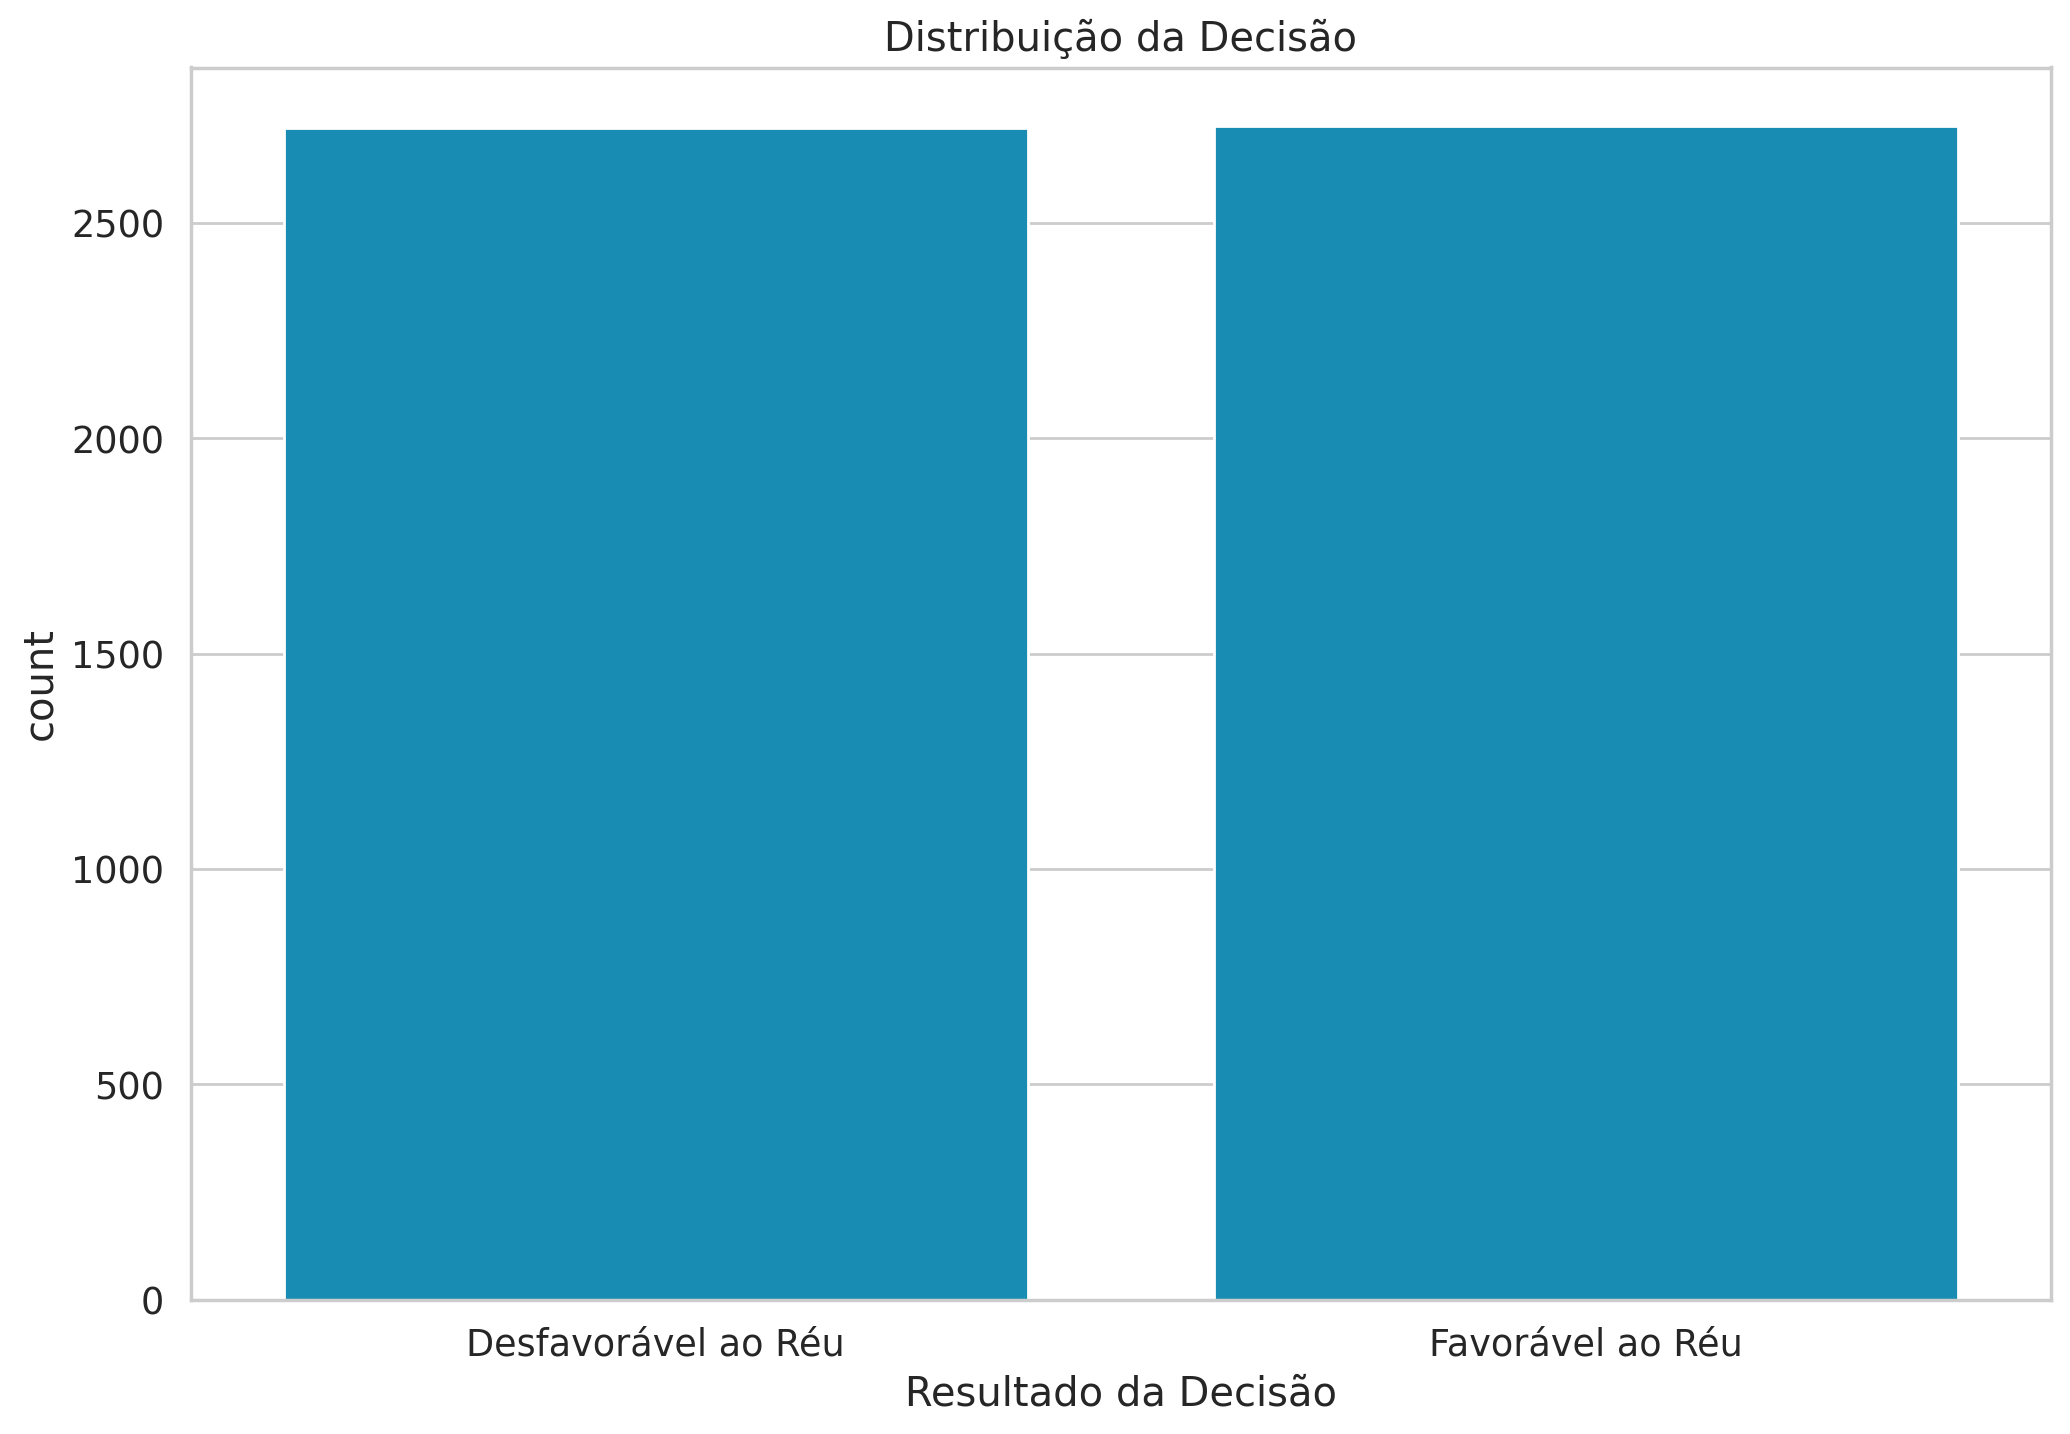

In [22]:
# Garantindo a ordem explícita das classes no gráfico (0 e 1)
ax = sns.countplot(x='classe', data=df, order=[1, 0])

# Fixando os ticks e os rótulos para refletir exatamente os valores 0 e 1
ax.set_xticks([1, 0])
ax.set_xticklabels(['Favorável ao Réu', 'Desfavorável ao Réu'])

plt.xlabel('Resultado da Decisão')
plt.title('Distribuição da Decisão')
plt.show()

In [23]:
# df[df['classe']==1]['RELATORIO'].tolist()[:2]

In [24]:
# df[df['classe']==0]['RELATORIO'].tolist()[:2]

In [25]:
#df['RELATORIO'] = df.RELATORIO.apply(pre_processamento)

In [26]:
# df[df['classe']==1]['RELATORIO'].tolist()[:1]

## BERT

In [27]:
from transformers import AutoTokenizer

# Tokenizer fast (Rust) reduz bastante o custo de pré-processamento
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, use_fast=True)

config.json:   0%|          | 0.00/865 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/568 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

In [28]:
# Some of the common BERT tokens
print(tokenizer.sep_token, tokenizer.sep_token_id) # marker for ending of a sentence
print(tokenizer.cls_token, tokenizer.cls_token_id) # start of each sentence, so BERT knows we’re doing classification
print(tokenizer.pad_token, tokenizer.pad_token_id) # special token for padding
print(tokenizer.unk_token, tokenizer.unk_token_id) # tokens not found in training set

[SEP] 102
[CLS] 101
[PAD] 0
[UNK] 100


BERT works with fixed-length sequences. We’ll use a simple strategy to choose the max length. Let’s store the token length of each review.

In [29]:
# # Store length of each review
# token_lens = []

# # Iterate through the content slide
# for text in df.RELATORIO:
#     #tokens = tokenizer.encode(text, max_length=1024)
#     tokens = tokenizer.encode(text)
#     token_lens.append(len(tokens))

In [30]:
# tokens_test = tokenizer.encode("O Habeas Corpus tem natureza constitucional.", truncation=True, max_length=160)
# #
# tokens_test

In [31]:
# for token in tokens_test:
#     print(f"token: {token} | value: {tokenizer.decode(token)}")

In [32]:
#get_word_from_token_id(101, tokenizer)
# tokenizer.convert_ids_to_tokens(101)

In [33]:
# tokenizer.decode(102)

In [34]:
# plt.figure(figsize=(12, 6))
# # Criando o gráfico de barras (histograma) das contagens absolutas
# sns.histplot(token_lens, bins=50, kde=False, color='#01BEFE')

# plt.title('Distribuição da Quantidade de Tokens por Registro')
# plt.xlabel('Quantidade de Tokens')
# plt.ylabel('Total de Registros')
# plt.xlim([0, 2000]) # Limitando o eixo x conforme o seu distplot anterior
# plt.show()

In [35]:
# plot the distribution of review lengths
# sns.distplot(token_lens)
# plt.xlim([0, 2000]);
# plt.xlabel('Token count')

### Preparing Torch Dataset

To enter data into a PyTorch, we need a more robust data generator class. We will return the review text as well to validate our predictions easily.

###  `HCAcordaoSTJ` (Custom Dataset)

A classe `HCAcordaoSTJ` (que herda de `torch.utils.data.Dataset`) atua como uma **ponte essencial entre os seus dados brutos e o modelo PyTorch/HuggingFace**. A criação desta classe customizada é uma prática padrão e necessária pelos seguintes motivos:

1. **Contrato com o PyTorch (`DataLoader`)**: Para que o `DataLoader` consiga gerenciar os lotes (batches), embaralhar os dados e usar múltiplos processadores, ele precisa saber como interagir com seus dados. O PyTorch exige que você implemente um contrato básico usando dois métodos:
   * `__len__`: Informa ao DataLoader o tamanho total do dataset.
   * `__getitem__`: Ensina o DataLoader a extrair e processar uma única linha (amostra) com base em um índice.

2. **Tokenização *On-the-Fly* (Sob Demanda) e Eficiência de Memória**: O método `__getitem__` aplica o `tokenizer` do HuggingFace individualmente em cada texto *apenas no momento em que a amostra é chamada* durante o treinamento. Em vez de tokenizar todo o seu dataset de 6336 acórdãos de uma vez e armazenar matrizes gigantescas na memória RAM, a transformação é feita lote a lote.

3. **Formatação Exigida pelo BERT**: Modelos da biblioteca `transformers` do HuggingFace não aceitam texto puro (strings). Eles esperam tensores (matrizes numéricas do PyTorch) com chaves muito específicas. O método `__getitem__` prepara e empacota exatamente o que o BERT precisa:
   * **`input_ids`**: O texto mapeado para os números do vocabulário do modelo.
   * **`attention_mask`**: Uma máscara de 1s e 0s que ensina o modelo a olhar apenas para as palavras reais e ignorar os espaços vazios (*padding*).

4. **Padronização Universal (*Padding* e *Truncation*)**: Redes neurais precisam que todas as entradas de um lote tenham o mesmo tamanho matemático. Como os acórdãos variam de tamanho, a classe força com que todos tenham exatamente `max_len` (no seu caso, 512 tokens). Textos menores são preenchidos com zeros (`padding='max_length'`) e textos maiores são cortados (`truncation=True`).

5. **Empacotamento dos Alvos (*Targets*)**: Além de formatar a entrada para o HuggingFace, a classe converte as suas classes (0 ou 1) no formato `torch.long`, que é o tipo de dado estritamente exigido pela função de perda (`CrossEntropyLoss`) do PyTorch durante a etapa de otimização.

Em resumo, o `HCAcordaoSTJ` é o "tradutor" que pega suas strings do Pandas e as transforma perfeitamente no idioma matemático e estrutural que o BERT e o PyTorch entendem.

In [36]:
from typing import Dict, Union
from torch.utils.data import Dataset

class HCAcordaoSTJ(Dataset):
    def __init__(self, reports: np.ndarray, targets: np.ndarray, tokenizer, max_len: int) -> Dataset:
        self.reports = reports.astype(str)
        self.targets = targets

        # Tokeniza uma vez (na construção do dataset), evitando custo repetido a cada época
        encodings = tokenizer(
            self.reports.tolist(),
            add_special_tokens=True,
            max_length=max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True
        )

        self.input_ids = torch.tensor(encodings['input_ids'], dtype=torch.long)
        self.attention_mask = torch.tensor(encodings['attention_mask'], dtype=torch.long)

    def __len__(self) -> int:
        return len(self.reports)

    def __getitem__(self, item: int) -> Dict[str, Union[str, torch.Tensor]]:
        return {
            'report_text': self.reports[item],
            'input_ids': self.input_ids[item],
            'attention_mask': self.attention_mask[item],
            'targets': torch.tensor(self.targets[item], dtype=torch.long)
        }

In [37]:
# dataset = HCAcordaoSTJ(
#     reports = ["Trata-se de habeas corpus.", "O presente recurso."],
#     targets = [0, 1],
#     tokenizer = tokenizer,
#     max_len = 32
# )

In [38]:
# item = dataset[1]
# print(item)

### Otimização de Memória
Manter apenas as colunas estritamente necessárias para o treinamento do modelo.

In [39]:
import gc

# Criar um novo DataFrame apenas com as colunas necessárias
df_clean = df[['RELATORIO', 'classe']].copy()

# Excluir o dataframe antigo da memória e forçar a coleta de lixo
del df
gc.collect()

# Renomear de volta para 'df' para manter a compatibilidade com o código abaixo
df = df_clean

print("Memória otimizada. Colunas atuais:", df.columns.tolist())
print("Novo shape do DataFrame:", df.shape)
display(df.head(3))

Memória otimizada. Colunas atuais: ['RELATORIO', 'classe']
Novo shape do DataFrame: (5445, 2)


,RELATORIO,classe
0,"Trata-se de habeas corpus, com pedido liminar,...",0
1,O EXMO. SR. MINISTRO REYNALDO SOARES DA FONSEC...,1
2,"Trata-se de habeas corpus, com pedido liminar,...",1


Create a 80% train data and 20% test.

In [40]:
from sklearn.model_selection import train_test_split

# Adicionado o parâmetro stratify para garantir a proporção das classes
df_train, df_test = train_test_split(df, test_size=TEST_SIZE_SPLIT, random_state=RANDOM_SEED, stratify=df['classe'])

print(f"Train shape: {df_train.shape}")
print(f"Test shape: {df_test.shape}")

print("\nDistribuição das classes no Treino:")
print(df_train['classe'].value_counts())

print("\nDistribuição das classes no Teste:")
print(df_test['classe'].value_counts())


Train shape: (4900, 2)
Test shape: (545, 2)

Distribuição das classes no Treino:
classe
0    2452
1    2448
Name: count, dtype: int64

Distribuição das classes no Teste:
classe
0    273
1    272
Name: count, dtype: int64


In [41]:
# 2/0

In [42]:
import os

# Definindo os caminhos completos para os arquivos
train_save_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_undersampling_min_treino.csv"
test_save_path = f"{BASE_PATH_DATASET}preprocessed_acordaos_HC_undersampling_min_teste.csv"

# Salvando os DataFrames em CSV (usando ponto e vírgula para manter o padrão do arquivo lido)
df_train.to_csv(train_save_path, sep=';', index=False)
df_test.to_csv(test_save_path, sep=';', index=False)

print(f"✅ Dataset de TREINO ({df_train.shape[0]} registros) salvo em:\n   -> {train_save_path}")
print(f"✅ Dataset de TESTE ({df_test.shape[0]} registros) salvo em:\n   -> {test_save_path}")

✅ Dataset de TREINO (4900 registros) salvo em:
   -> /content/drive/MyDrive/_Mestrado PUCPR/Datasets/preprocessed_acordaos_HC_undersampling_min_treino.csv
✅ Dataset de TESTE (545 registros) salvo em:
   -> /content/drive/MyDrive/_Mestrado PUCPR/Datasets/preprocessed_acordaos_HC_undersampling_min_teste.csv


In [43]:
#Você parou nesta etapa. Agora vc precisa estudar em detalhes a classe DataLoader e as implicações com o treinamento.

Create a dataloader to release data in batches.

### O papel do DataLoader neste treinamento

O `DataLoader` em PyTorch é uma utilidade fundamental para o treinamento de modelos de aprendizado profundo, especialmente com grandes conjuntos de dados. No contexto deste treinamento BERT, ele desempenha vários papéis cruciais:

1.  **Iteração em Lotes (Batching)**: Ele agrupa os dados em pequenos lotes (definidos por `batch_size`). Em vez de alimentar uma única amostra para o modelo por vez (o que é ineficiente para GPUs), o `DataLoader` fornece um lote de amostras. Isso permite que o modelo processe várias entradas simultaneamente, acelerando o treinamento e aproveitando a paralelização do hardware.

2.  **Embaralhamento (Shuffling)**: Antes de cada época de treinamento, o `DataLoader` (se configurado com `shuffle=True`, embora neste notebook esteja implícito que não está explícito no `create_data_loader` mas é uma prática comum para o treinamento) embaralha os dados. Isso é vital para garantir que o modelo não aprenda a ordem dos dados e para evitar que a ordem das amostras introduza vieses no treinamento.

3.  **Processamento Multiprocessado (`num_workers`)**: O parâmetro `num_workers` permite que os dados sejam carregados e pré-processados em paralelo por múltiplos processos secundários (em vez do processo principal). Isso é particularmente útil quando o pré-processamento de dados é uma etapa demorada (como a tokenização e o padding feitos na classe `HCAcordaoSTJ`), pois evita gargalos no carregamento de dados que poderiam deixar a GPU ociosa.

4.  **Integração com `Dataset`**: O `DataLoader` trabalha em conjunto com a classe `Dataset` (neste caso, `HCAcordaoSTJ`). A classe `Dataset` é responsável por como as amostras individuais são carregadas e pré-processadas (tokenização, truncamento, padding, etc.), enquanto o `DataLoader` é responsável por como essas amostras individuais são agrupadas e fornecidas ao modelo em lotes.

Em resumo, o `DataLoader` otimiza o fluxo de dados do disco para a memória e, em seguida, para o modelo, garantindo que o treinamento seja eficiente, reprodutível (com `random_state`) e que o modelo veja os dados de forma variada ao longo das épocas, o que é fundamental para um bom desempenho e generalização.

In [44]:
import os
from torch.utils.data import DataLoader

def create_data_loader(df: pd.DataFrame, tokenizer, max_len: int, batch_size: int, shuffle: bool = False) -> DataLoader:
    ds = HCAcordaoSTJ(
        reports=df.RELATORIO.to_numpy(),
        targets=df.classe.to_numpy(),
        tokenizer=tokenizer,
        max_len=max_len
    )

    workers = min(NUM_WORKERS, os.cpu_count() or 0)

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=workers,
        pin_memory=(device.type == 'cuda'),
        persistent_workers=(workers > 0)
    )

In [45]:
# Create train and test data loaders
train_data_loader = create_data_loader(df_train, tokenizer, MAX_LEN, BATCH_SIZE, shuffle=True)
test_data_loader = create_data_loader(df_test, tokenizer, MAX_LEN, BATCH_SIZE, shuffle=False)

In [46]:
# Examples
data = next(iter(train_data_loader))
print(data.keys())

print(data['input_ids'].shape)
print(data['attention_mask'].shape)
print(data['targets'].shape)

dict_keys(['report_text', 'input_ids', 'attention_mask', 'targets'])
torch.Size([16, 512])
torch.Size([16, 512])
torch.Size([16])


## Sentiment Classification with BERT and Hugging Face

We’ll use the basic BertModel and build our sentiment classifier on top of it. Let’s load the model

##### Load the basic BERT model
bert_model = BertModel.from_pretrained(MODEL_NAME)

We use a dropout layer for some regularization and a fully-connected layer for our output. We are returning the raw output of the last layer since that is required for the cross-entropy loss function in PyTorch to work. Create an instance and move it to the GPU

In [47]:
# num_layers_to_freeze = LAYERS_TO_FREEZE
# print(f"Freezing the embeddings and the first {num_layers_to_freeze} encoder layers of the model...")

# for name, param in bert_model.named_parameters():
#     if 'embeddings' in name:
#         param.requires_grad = False
#     elif 'encoder.layer' in name:
#         # Extrai o número da camada pelo nome (ex: bert.encoder.layer.0.attention...)
#         layer_num = int(name.split('.')[3])
#         if layer_num < num_layers_to_freeze:
#             param.requires_grad = False
#         else:
#             # Garante que camadas subsequentes sejam treináveis
#             param.requires_grad = True
#     else:
#         # O pooler e o classifier (camadas finais) continuam treináveis
#         param.requires_grad = True

# print("Layers freezing complete. You can now proceed with training.")

In [48]:
# Print layer names
# The index can help you identify which layers correspond to earlier blocks (e.g., embedding, early encoder layers)
# i = 0
# for name, param in bert_model.named_parameters():
#   i = i + 1
#   print(f"index: {i} {name} - status: {param.requires_grad}")

In [49]:
# Habilitar apenas para fins de depuração. A ativação desta célula acarretará em
#   redução de performance.

# import os
# os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

### O papel da classe HCAcordaoClassifier no fine-tuning

A classe HCAcordaoClassifier adapta o encoder BERT para classificacao binaria de decisoes judiciais (Favoravel vs Desfavoravel ao Reu), combinando transferencia de aprendizado com regularizacao estrutural.

1. Base pre-treinada (BERT):
- O bloco self.bert usa representacoes contextuais profundas para extracao de features juridicas.
- Embasamento: Devlin et al. (2019), BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.

2. Cabeca de classificacao otimizada (768 -> 256 -> 128 -> 2):
- A cabeca foi reduzida para evitar excesso de parametros na parte supervisionada, diminuindo risco de overfitting em dataset de tamanho moderado.
- Camadas totalmente conectadas (nn.Linear) mantem capacidade de separacao nao linear com custo computacional menor do que cabecas superdimensionadas.

3. Normalizacao e estabilizacao do treinamento:
- LayerNorm (entrada e entre blocos): estabiliza distribuicoes internas em arquiteturas Transformer e melhora robustez numerica.
- BatchNorm1d nas camadas densas: acelera convergencia e melhora estabilidade do gradiente.
- Embasamento: Ba et al. (2016), Layer Normalization; Ioffe and Szegedy (2015), Batch Normalization.

4. Ativacao e regularizacao:
- ReLU apos camadas densas para introduzir nao linearidade com baixo custo computacional.
- Dropout progressivo (0.2 e 0.3) para reduzir co-adaptacao de neuronios e mitigar overfitting.
- Embasamento: Nair and Hinton (2010), Rectified Linear Units; Srivastava et al. (2014), Dropout.

5. Decisao de congelamento parcial (etapa preliminar):
- Nesta etapa, o treinamento congela 22 das 24 camadas encoder do BERT Large e ajusta apenas as 2 camadas superiores do encoder (alem da cabeca classificadora).
- Racional tecnico: preservar conhecimento linguistico-juridico geral do backbone e reduzir variancia de treinamento em base supervisionada moderada.
- Essa estrategia e compativel com a literatura de transfer learning e parameter-efficient adaptation, que mostra que adaptacao parcial pode manter desempenho com menor custo e menor risco de overfitting.
- Embasamento: Howard and Ruder (2018), Universal Language Model Fine-tuning; Houlsby et al. (2019), Parameter-Efficient Transfer Learning for NLP; Zaken et al. (2022), BitFit; Sun et al. (2019), How to Fine-Tune BERT for Text Classification.

Em resumo, a arquitetura atual busca equilibrio entre capacidade preditiva, estabilidade de otimizacao e controle de overfitting, mantendo compatibilidade com o fluxo de fine-tuning do BERT.

In [ ]:
from transformers import BertModel
from torch import nn

class HCAcordaoClassifier(nn.Module):

    def __init__(self, n_classes: int, num_layers_to_freeze: int, model_name: str) -> None:
        super(HCAcordaoClassifier, self).__init__()
        # Utilizamos o BertModel puro (base) para extração de features
        self.bert = BertModel.from_pretrained(model_name)

        # Arquitetura otimizada: LayerNorm + FC intermediárias + BatchNorm + Dropout variável
        # Camada 1: Redução com normalização
        self.norm_input = nn.LayerNorm(self.bert.config.hidden_size)
        self.fc1 = nn.Linear(self.bert.config.hidden_size, 256)
        self.bn1 = nn.BatchNorm1d(256)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(p=0.2)  # Dropout moderado na primeira camada
        
        # Camada 2: Intermediária com normalização
        self.norm1 = nn.LayerNorm(256)
        self.fc2 = nn.Linear(256, 128)
        self.bn2 = nn.BatchNorm1d(128)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(p=0.3)  # Dropout aumentado na segunda camada
        
        # Camada final de classificação
        self.norm2 = nn.LayerNorm(128)
        self.out = nn.Linear(128, n_classes)

        # Executa o congelamento das camadas logo após a inicialização
        self.freeze_layers(num_layers_to_freeze)

    def freeze_layers(self, num_layers_to_freeze: int) -> None:
      print(f"Freezing the embeddings and the first {num_layers_to_freeze} encoder layers of the model...")

      for name, param in self.bert.named_parameters():
          if 'embeddings' in name:
              param.requires_grad = False
          elif 'encoder.layer' in name:
              # Extrai o número da camada pelo nome (ex: encoder.layer.0.attention...)
              layer_num = int(name.split('.')[2])
              if layer_num < num_layers_to_freeze:
                  param.requires_grad = False
              else:
                  # Garante que camadas subsequentes sejam treináveis
                  param.requires_grad = True
          else:
              # O pooler e o classifier (camadas finais) continuam treináveis
              param.requires_grad = True

      print("Layers freezing complete. You can now proceed with training.")

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        # Saída do BERT
        output = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Representação inicial da sentença (pooled_output)
        cls_embedding = output.pooler_output

        # Passagem pelas camadas intermediárias (hidden layers)
        # Camada 1 com normalização
        hidden = self.norm_input(cls_embedding)
        hidden = self.fc1(hidden)
        hidden = self.bn1(hidden)
        hidden = self.relu1(hidden)
        hidden = self.drop1(hidden)
        
        # Camada 2 com normalização
        hidden = self.norm1(hidden)
        hidden = self.fc2(hidden)
        hidden = self.bn2(hidden)
        hidden = self.relu2(hidden)
        hidden = self.drop2(hidden)
        
        # Normalização antes da camada de saída
        hidden = self.norm2(hidden)

        # Saída final crua
        logits = self.out(hidden)

        return logits

In [51]:
# Instantiate the model and move to classifier
model = HCAcordaoClassifier(len(class_names), LAYERS_TO_FREEZE, MODEL_CHECKPOINT)
model = model.to(device)

# O config pertence ao modelo base do BERT (self.bert na nossa classe)
print(model.bert.config.hidden_size)

if USE_TORCH_COMPILE and device.type == 'cuda' and hasattr(torch, 'compile'):
    model = torch.compile(model)

pytorch_model.bin:   0%|          | 0.00/1.34G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: rufimelo/Legal-BERTimbau-large
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Freezing the embeddings and the first 20 encoder layers of the model...
Layers freezing complete. You can now proceed with training.


model.safetensors:   0%|          | 0.00/1.34G [00:00<?, ?B/s]

1024


#### Caracteristicas do modelo e justificativa tecnica

In [52]:
# Number of hidden units
# from transformers import BertModel

# bert_model = BertModel.from_pretrained(MODEL_CHECKPOINT)
# print(bert_model.config.hidden_size)

### Fase de treinamento e embasamento cientifico

A configuracao de treinamento foi ajustada para melhorar estabilidade, calibracao das probabilidades e robustez da convergencia no fine-tuning.

1. Otimizacao com AdamW + AMSGrad:
- O treino usa AdamW com weight decay desacoplado, que corrige a aplicacao de regularizacao em relacao ao Adam classico.
- O modo AMSGrad e usado para maior estabilidade em cenarios com dinamica de gradiente mais irregular.
- Embasamento: Loshchilov and Hutter (2019), Decoupled Weight Decay Regularization; Reddi et al. (2018), On the Convergence of Adam and Beyond.

2. Loss para classificacao multiclasse sem Softmax explicito:
- CrossEntropyLoss recebe logits crus (sem camada Softmax no modelo), estrategia numericamente estavel e padrao para classificacao supervisionada.
- Embasamento: Goodfellow, Bengio and Courville (2016), Deep Learning.

3. Label smoothing (0.1):
- Label smoothing reduz excesso de confianca do modelo e melhora calibracao de probabilidade, especialmente util em tarefas com fronteiras de classe semanticas proximas.
- Embasamento: Szegedy et al. (2016), Rethinking the Inception Architecture for Computer Vision.

4. Controle de gradiente:
- Gradient clipping por norma (max_norm=5.0) reduz risco de gradientes explosivos e estabiliza atualizacoes durante o treino.
- Embasamento: Pascanu, Mikolov and Bengio (2013), On the difficulty of training recurrent neural networks.

5. Mixed Precision (AMP):
- Autocast e GradScaler reduzem consumo de memoria e aumentam throughput em GPU, mantendo estabilidade numerica.
- Embasamento: Micikevicius et al. (2018), Mixed Precision Training.

6. Scheduler:
- O scheduler linear com warmup esta ativo no fluxo principal, pratica amplamente adotada em fine-tuning de Transformer.
- O scheduler cosine com warm restarts esta instanciado para experimentacao futura, mas nao esta conectado ao loop principal neste estado do notebook.
- Embasamento: Devlin et al. (2019) para warmup em BERT; Loshchilov and Hutter (2017), SGDR: Stochastic Gradient Descent with Warm Restarts.

Essa configuracao prioriza estabilidade do processo de treino, melhor calibracao das probabilidades preditas e eficiencia computacional, sem alterar os criterios de selecao do melhor modelo definidos no projeto.

### Referencias bibliograficas

- Ba, J. L., Kiros, J. R., and Hinton, G. E. (2016). Layer Normalization. arXiv:1607.06450.
- Devlin, J., Chang, M. W., Lee, K., and Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. NAACL-HLT 2019.
- Goodfellow, I., Bengio, Y., and Courville, A. (2016). Deep Learning. MIT Press.
- Howard, J., and Ruder, S. (2018). Universal Language Model Fine-tuning for Text Classification. ACL 2018.
- Houlsby, N., Giurgiu, A., Jastrzebski, S., et al. (2019). Parameter-Efficient Transfer Learning for NLP. ICML 2019.
- Ioffe, S., and Szegedy, C. (2015). Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift. ICML 2015.
- Loshchilov, I., and Hutter, F. (2017). SGDR: Stochastic Gradient Descent with Warm Restarts. ICLR 2017.
- Loshchilov, I., and Hutter, F. (2019). Decoupled Weight Decay Regularization. ICLR 2019.
- Micikevicius, P., Narang, S., Alben, J., et al. (2018). Mixed Precision Training. ICLR 2018.
- Nair, V., and Hinton, G. E. (2010). Rectified Linear Units Improve Restricted Boltzmann Machines. ICML 2010.
- Pascanu, R., Mikolov, T., and Bengio, Y. (2013). On the difficulty of training recurrent neural networks. ICML 2013.
- Reddi, S. J., Kale, S., and Kumar, S. (2018). On the Convergence of Adam and Beyond. ICLR 2018.
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., and Salakhutdinov, R. (2014). Dropout: A Simple Way to Prevent Neural Networks from Overfitting. JMLR, 15.
- Sun, C., Qiu, X., Xu, Y., and Huang, X. (2019). How to Fine-Tune BERT for Text Classification?. CCL 2019.
- Szegedy, C., Vanhoucke, V., Ioffe, S., Shlens, J., and Wojna, Z. (2016). Rethinking the Inception Architecture for Computer Vision. CVPR 2016.
- Yosinski, J., Clune, J., Bengio, Y., and Lipson, H. (2014). How transferable are features in deep neural networks?. NeurIPS 2014.
- Zaken, E. B., Goldberg, Y., and Ravfogel, S. (2022). BitFit: Simple Parameter-efficient Fine-tuning for Transformer-based Masked Language-models. ACL 2022.

In [ ]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts

# Optimizer AdamW com AMSGrad para melhor estabilidade e epsilon reduzido para precisão
optimizer = AdamW(
    model.parameters(), 
    lr=LEARNING_RATE, 
    weight_decay=WEIGHT_DECAY,
    eps=1e-7,      # Epsilon reduzido para maior precisão numérica
    amsgrad=True   # Ativa AMSGrad para melhor convergência
)

# Number of iterations usando a variável global EPOCHS
total_steps = len(train_data_loader) * EPOCHS

# Calculando os passos de warmup com base no WARMUP_RATIO
warmup_steps = int(total_steps * WARMUP_RATIO)

# Scheduler híbrido: Linear warmup seguido de cosine annealing
scheduler_warmup = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# Scheduler cosine annealing com warm restarts para exploração de múltiplos minima
scheduler_cosine = CosineAnnealingWarmRestarts(optimizer, T_0=20, T_mult=2, eta_min=1e-7)

# Usar o warmup no início e cosine annealing depois
scheduler = scheduler_warmup

# Loss function com Label Smoothing para melhor calibração de confiança do modelo
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1).to(device)

# AMP acelera treino em GPU e reduz uso de memória
use_amp = (device.type == 'cuda')
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Function for a single training iteration
def train_epoch(model, data_loader, loss_fn, optimizer, device, scheduler, n_examples, scaler, use_amp):
    model = model.train()
    losses = []
    correct_predictions = 0
    all_preds = []
    all_targets = []

    optimizer.zero_grad(set_to_none=True)

    for d in data_loader:
        input_ids = d["input_ids"].to(device, non_blocking=True)
        attention_mask = d["attention_mask"].to(device, non_blocking=True)
        targets = d["targets"].to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            loss = loss_fn(outputs, targets)

        _, preds = torch.max(outputs, dim=1)

        correct_predictions += torch.sum(preds == targets)
        losses.append(loss.item())

        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())

        # Backward prop (mixed precision)
        scaler.scale(loss).backward()

        # Gradient Descent com clipping adaptativo
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)  # Clipping menos agressivo
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)

    acc = (correct_predictions.double() / n_examples).item()
    loss_val = np.mean(losses)
    precision = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    return acc, loss_val, precision, recall, f1

Write a function to evaluate model performance

In [55]:
def eval_model(model, data_loader, loss_fn, device, n_examples, use_amp=False):
    model = model.eval()

    losses = []
    correct_predictions = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for d in data_loader:
            input_ids = d["input_ids"].to(device, non_blocking=True)
            attention_mask = d["attention_mask"].to(device, non_blocking=True)
            targets = d["targets"].to(device, non_blocking=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                # Get model outputs
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )
                loss = loss_fn(outputs, targets)

            _, preds = torch.max(outputs, dim=1)

            correct_predictions += torch.sum(preds == targets)
            losses.append(loss.item())

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    acc = (correct_predictions.double() / n_examples).item()
    loss_val = np.mean(losses)
    precision = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    return acc, loss_val, precision, recall, f1

Write the training Loop and store the best training state.

In [ ]:
%%time
import copy
from collections import defaultdict
import os

history = defaultdict(list)
best_recall = 0
best_model_weights = None

# Parâmetros para o Early Stopping
patience = EARLY_STOPPING
epochs_no_improve = 0

# Garantir que a pasta models exista
model_dir = f'{BASE_PATH_GENERAL}models'
os.makedirs(model_dir, exist_ok=True)
model_save_path = f'{model_dir}/{MODEL_NAME_SAVED}.bin'

for epoch in range(EPOCHS):

    # Show details
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("-" * 70)

    train_acc, train_loss, train_prec, train_rec, train_f1 = train_epoch(
        model,
        train_data_loader,
        loss_fn,
        optimizer,
        device,
        scheduler,
        len(df_train),
        scaler,
        use_amp
    )

    print(f"Train loss {train_loss:.4f} accuracy {train_acc:.4f} precision {train_prec:.4f} recall {train_rec:.4f} f1 {train_f1:.4f}")

    # Get model performance on test set
    test_acc, test_loss, test_prec, test_rec, test_f1 = eval_model(
        model,
        test_data_loader,
        loss_fn,
        device,
        len(df_test),
        use_amp
    )

    print(f"Test  loss {test_loss:.4f} accuracy {test_acc:.4f} precision {test_prec:.4f} recall {test_rec:.4f} f1 {test_f1:.4f}")
    print()

    history['train_acc'].append(round(train_acc, 5))
    history['train_loss'].append(round(train_loss, 5))
    history['train_prec'].append(round(train_prec, 5))
    history['train_rec'].append(round(train_rec, 5))
    history['train_f1'].append(round(train_f1, 5))

    history['test_acc'].append(round(test_acc, 5))
    history['test_loss'].append(round(test_loss, 5))
    history['test_prec'].append(round(test_prec, 5))
    history['test_rec'].append(round(test_rec, 5))
    history['test_f1'].append(round(test_f1, 5))

    # If we beat prev performance
    if test_rec > best_recall:
        best_model_weights = copy.deepcopy(model.state_dict())
        best_recall = test_rec
        epochs_no_improve = 0 # Reseta o contador ao melhorar
    else:
        epochs_no_improve += 1
        print(f"Sem melhoras no teste por {epochs_no_improve} época(s).")
        if epochs_no_improve >= patience:
            print(f"Early Stopping acionado! Treinamento interrompido na época {epoch + 1}.")
            break

# Após o término do treinamento, salva o melhor modelo em disco
if best_model_weights is not None:
    torch.save(best_model_weights, model_save_path)
    print(f"Treinamento finalizado. Melhor modelo (Recall: {best_recall:.4f}) salvo em: {model_save_path}")

Epoch 1/200
----------------------------------------------------------------------
Train loss 0.6881 accuracy 0.5304 precision 0.5409 recall 0.5306 f1 0.4990
Test  loss 0.6749 accuracy 0.6202 precision 0.6280 recall 0.6204 f1 0.6145

Epoch 2/200
----------------------------------------------------------------------
Train loss 0.6361 accuracy 0.6608 precision 0.6641 recall 0.6609 f1 0.6592
Test  loss 0.5360 accuracy 0.7670 precision 0.7889 recall 0.7667 f1 0.7624

Epoch 3/200
----------------------------------------------------------------------


The above took a lot of time but it's finally working. Now, we can plot the training and validation accuracy.

In [ ]:
plt.plot(history['train_loss'], label='training loss')
plt.plot(history['test_loss'], label='validation loss')

plt.title('Training history')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.ylim([0, 2]);

### Model Evaluation

In [ ]:
# Carrega os melhores pesos encontrados durante o treinamento para avaliação
if 'best_model_weights' in locals() and best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Melhores pesos do modelo carregados para avaliação!")

test_acc, test_loss, test_prec, test_rec, test_f1 = eval_model(
  model,
  test_data_loader,
  loss_fn,
  device,
  len(df_test)
)

print(f"Test Accuracy: {test_acc:.2f}")
print(f"Test Precision: {test_prec:.2f}")
print(f"Test Recall: {test_rec:.2f}")
print(f"Test F1: {test_f1:.2f}")


Define a helper function to get predictions from our models. This is similar to the evaluation function, except that we’re storing the text of the reviews and the predicted probabilities

In [ ]:
def get_predictions(model, data_loader):
    model = model.eval()

    report_texts = []
    predictions = []
    prediction_probs = []
    real_values = []

    with torch.no_grad():
        for d in data_loader:
            texts = d["report_text"]
            input_ids = d["input_ids"].to(device)
            attention_mask = d["attention_mask"].to(device)
            targets = d["targets"].to(device)

            # Get outputs
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            _, preds = torch.max(outputs, dim=1)

            report_texts.extend(texts)
            predictions.extend(preds)
            prediction_probs.extend(outputs)
            real_values.extend(targets)

    predictions = torch.stack(predictions).cpu()
    prediction_probs = torch.stack(prediction_probs).cpu()
    real_values = torch.stack(real_values).cpu()

    return report_texts, predictions, prediction_probs, real_values

In [ ]:
y_report_texts, y_pred, y_pred_probs, y_test = get_predictions(
    model,
    test_data_loader
)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=class_names))

In [ ]:
from sklearn.metrics import confusion_matrix

def show_confusion_matrix(confusion_matrix):
    hmap = sns.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues")
    hmap.yaxis.set_ticklabels(hmap.yaxis.get_ticklabels(), rotation=0, ha='right')
    hmap.xaxis.set_ticklabels(hmap.xaxis.get_ticklabels(), rotation=30, ha='right')
    plt.ylabel('True Decisions')
    plt.xlabel('Predicted Decisions');

cm = confusion_matrix(y_test, y_pred)
df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)
show_confusion_matrix(df_cm)

### Curva ROC e Métrica AUC
Avaliando a capacidade do modelo de distinguir entre as classes.

In [ ]:
import torch.nn.functional as F
from sklearn.metrics import roc_curve, auc

# 1. Preparar os dados reais e as probabilidades
# y_test já contém as classes reais geradas pela função get_predictions (0 ou 1)
y_true = y_test.numpy()

# Converter logits (saídas brutas) em probabilidades para a classe positiva (1 - Favorável)
probs = F.softmax(y_pred_probs, dim=1).numpy()
y_scores = probs[:, 1] # Pegando apenas a probabilidade da classe 1

# 2. Calcular FPR (Taxa de Falsos Positivos) e TPR (Taxa de Verdadeiros Positivos)
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

# 3. Calcular a Área Sob a Curva (AUC)
roc_auc = auc(fpr, tpr)

# 4. Plotar a Curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#FF7D00', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')

# Plotar a linha de base (modelo aleatório)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',)

# Configurações do gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC (Base de Teste)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3, linestyle='--')

plt.show()

print(f"Métrica AUC: {roc_auc:.4f}")

## Predicting on raw text

In [ ]:
def BERT_SA(text) :
    encoded_review = tokenizer(text,
                              max_length=MAX_LEN,add_special_tokens=True,
                              return_token_type_ids=False,pad_to_max_length=True,
                              return_attention_mask=True,return_tensors='pt')

    input_ids = encoded_review['input_ids'].to(device)
    attention_mask = encoded_review['attention_mask'].to(device)

    # Garante que o modelo está no modo de avaliação e economiza memória
    model.eval()
    with torch.no_grad():
        output = model(input_ids, attention_mask)

    # Calcula as probabilidades usando softmax
    probs = F.softmax(output, dim=1)[0]
    _, prediction = torch.max(output, dim=1)

    print(f'Report: {text}\n')
    print(f'Decision  : {class_names[prediction]}')
    print('Probabilidades:')
    print(f' - {class_names[0]}: {probs[0].item() * 100:.2f}%')
    print(f' - {class_names[1]}: {probs[1].item() * 100:.2f}%')

In [ ]:
def bert_vall(text, valor_real, model):
    encoded_review = tokenizer(text,
                              max_length=MAX_LEN, add_special_tokens=True,
                              return_token_type_ids=False, pad_to_max_length=True,
                              return_attention_mask=True, return_tensors='pt')

    input_ids = encoded_review['input_ids'].to(device)
    attention_mask = encoded_review['attention_mask'].to(device)

    # Garante que o modelo está no modo de avaliação e economiza memória
    model.eval()
    with torch.no_grad():
        output = model(input_ids, attention_mask)

    # Calcula as probabilidades usando softmax
    probs = F.softmax(output, dim=1)[0]
    prob_desfavoravel = probs[0].item()
    prob_favoravel = probs[1].item()

    # Obtém a classe prevista
    _, prediction = torch.max(output, dim=1)
    predicted_class_idx = prediction.item()
    predicted_class_name = class_names[predicted_class_idx]

    # Compara o valor previsto com o valor real passado
    # Permite comparar passando tanto o int (0 ou 1) quanto a string ('Favorável ao Réu' etc)
    if isinstance(valor_real, int):
        acertou = (predicted_class_idx == valor_real)
    else:
        acertou = (predicted_class_name == valor_real)

    return acertou, prob_desfavoravel, prob_favoravel

# Exemplo de uso:
# acertou, prob_desf, prob_fav = bert_vall("texto do relatorio...", 1, loaded_model)
# print(f"Acertou? {acertou} | Prob. Desfavorável: {prob_desf*100:.2f}% | Prob. Favorável: {prob_fav*100:.2f}%")

In [ ]:
# texto = """<br>O ministro relator (SEBASTIÃO REIS): Trata-se de habeas: corpus <b>substitutivo de recurso próprio</b>, com pedido de liminar, impetrado em favor de LUIS FELIPE SILVA DE ASSIS, em que se aponta com autoridade coatora o Tribunal de Justiça do Estado do Rio de Janeiro.Consta dos autos que o paciente foi condenado à pena de 5 anos e 10 meses de reclusão, em regime semiaberto, mais pagamento de 583 dias-multa, como incurso no art. 33,caput, c.c o 40, VI, da Lei n. 11.343/2006.Em sede recursal, o Tribunal de origem negou provimento ao apelo defensivo."""
# texto = pre_processamento(texto, mantem_pontuacao='n')

# BERT_SA(texto)